# MAPPING OF HUMAN DEVELOPMENT INDICES FOR THE 9TH KNHDR
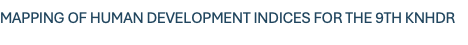
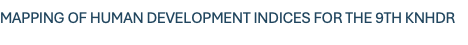
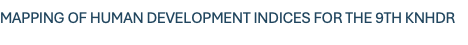
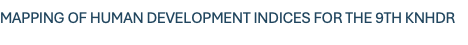

In [9]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patheffects as path_effects
import numpy as np

## Loading Shapefiles for Kenyan Map with Counties

<Axes: >

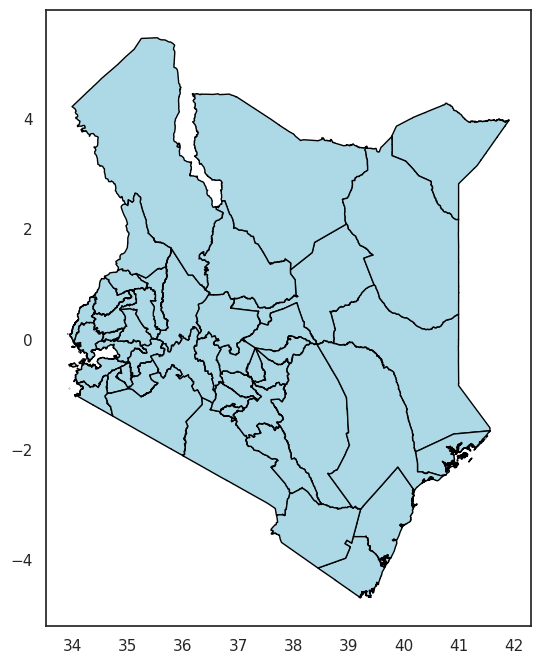

In [10]:
# 1. Load Data
# Load the shapefile containing Kenya county boundaries
# Ensure the county names in the shapefile match the spelling in your excel file
gdf = gpd.read_file('/kaggle/input/datasets/lekakeny/kenya-counties-map/ke_county.shp')
# 2. Plot the basic map geometry
gdf.plot(edgecolor='black', facecolor='lightblue', figsize=(8, 8))

# 3. Display the map (required if running in a script)
# plt.title("County Boundaries Map")
# plt.show()

In [11]:
# print(gdf.columns)
type(gdf)
gdf.shape
gdf.columns
# gdf


Index(['gid', 'county', 'pop 2009', 'lf_endemic', 'country', 'counts',
       'var1_class', 'hiv_class', 'hiv_his_cl', 'cuid', 'geometry'],
      dtype='object')

## Human Development Index
### 1. Mapping HDI to Kenyan Map with Counties

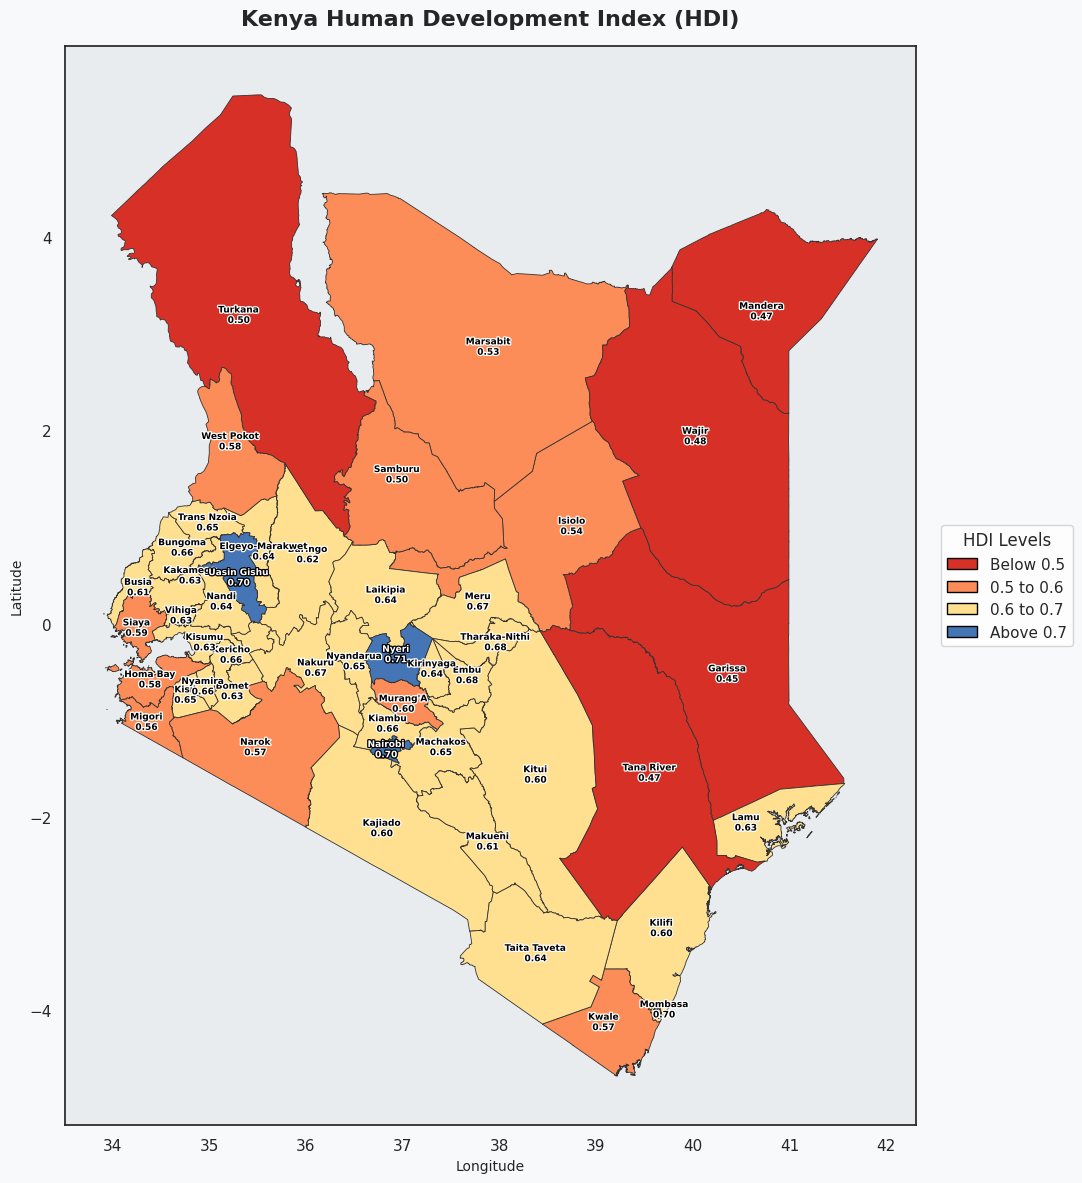

In [12]:
# Load your HDI data
hdi_data = pd.read_excel('/kaggle/input/datasets/lekakeny/human-development-report/2026 HDI Revised.xlsx', sheet_name='HDI', header=1)
hdi_data = hdi_data.rename(columns={'Unnamed: 1': 'County', 'HDI': 'HDI_Score'})
hdi_data = hdi_data.dropna(subset=['County', 'HDI_Score'])
hdi_data.at[44, 'County'] = "HOMA BAY"
hdi_data.at[27, 'County'] = "Trans Nzoia"

# 2. Merge Geospatial and HDI Data
# Merge on the county name. Convert both to upper/title case to ensure they match perfectly.
gdf['County_Name'] = gdf['county'].str.strip().str.title()
hdi_data['County'] = hdi_data['County'].str.strip().str.title()

map_data = gdf.merge(hdi_data, left_on='County_Name', right_on='County', how='left')

# 3. Categorize HDI Values (4 active bins)
# 5 bin edges createTo create 4 distinct labels, you must provide 5 bin edges (since `pd.cut` creates bins *between* the edges). By adding a starting edge of `0.0`, you create 4 complete categories. 

#For the colors, a high-contrast diverging palette (Red to Blue) is the standard for mapping human development, as it intuitively signals the transition from critical/low development (warm colors) to high development (cool colors).


# 3. Categorize HDI Values (4 bins)
# 5 bin edges create 4 categories
bins = [0.0, 0.5, 0.6, 0.7, 1.0]
labels = ['Below 0.5', '0.5 to 0.6', '0.6 to 0.7', 'Above 0.7']

# Apply categorization
map_data['HDI_Category'] = pd.cut(map_data['HDI_Score'], bins=bins, labels=labels, right=False)

# Updated 4-color high-contrast palette
color_mapping = {
    'Below 0.5': '#d73027',   # Red (Lowest HDI)
    '0.5 to 0.6': '#fc8d59',  # Orange (Low-Medium HDI)
    '0.6 to 0.7': '#fee090',  # Yellow (Medium-High HDI)
    'Above 0.7': '#4575b4'    # Blue (Highest HDI)
}

# Assign colors. Fill any unexpected NaNs with a neutral gray.
# map_data['Color'] = map_data['HDI_Category'].map(color_mapping).fillna('#e0e0e0')

# Create a color column based on the category
map_data['Color'] = map_data['HDI_Category'].map(color_mapping)

# 4. Plotting
fig, ax = plt.subplots(1, 1, figsize=(12, 12), facecolor='#f8f9fa')
ax.set_facecolor('#e9ecef') # Set background grid color matching the image

# Plot the base map using the assigned colors
map_data.plot(
    ax=ax, 
    color=map_data['Color'], 
    edgecolor='#333333', 
    linewidth=0.6
)

# 5. Add Enhanced County Labels & Values
for idx, row in map_data.iterrows():
    if pd.notna(row['HDI_Score']):
        label_text = f"{row['County']}\n{row['HDI_Score']:.2f}"
        
        # Use representative_point() to guarantee the point is inside the county polygon
        point = row['geometry'].representative_point()
        x, y = point.x, point.y
        
        # Determine text color dynamically based on background
        category = str(row['HDI_Category'])
        text_color = 'white' if category in ['0.4 to 0.5', 'Above 0.7'] else 'black'
        stroke_color = 'black' if text_color == 'white' else 'white'

        txt = ax.annotate(
            text=label_text, 
            xy=(x, y), 
            fontsize=6.5, 
            ha='center', 
            va='center',
            color=text_color,
            weight='bold'
        )
        
        # Add stroke/halo effect around text so it pops on any fill color
        txt.set_path_effects([
            path_effects.withStroke(linewidth=1.8, foreground=stroke_color)
        ])

# 6. Formatting & Legend
plt.title("Kenya Human Development Index (HDI)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Longitude", fontsize=10)
plt.ylabel("Latitude", fontsize=10)

legend_elements = [
    Patch(facecolor=color_mapping[label], edgecolor='black', label=label) 
    for label in labels
]
# legend_elements.append(Patch(facecolor='#e0e0e0', edgecolor='black', label='No Data'))

ax.legend(
    handles=legend_elements, 
    loc='center left', 
    bbox_to_anchor=(1.02, 0.5), 
    title="HDI Levels",
    frameon=True,
    facecolor='white'
)

# ax.grid(True, color='white', linestyle='--', linewidth=0.8, alpha=0.7)
# ax.xaxis.set_major_formatter('{x:1.0f}°E')
# ax.yaxis.set_major_formatter('{x:1.0f}°N')

plt.tight_layout()
# plt.savefig('kenya_hdi_map.png', dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

### 2. Life Expectancy Index by County

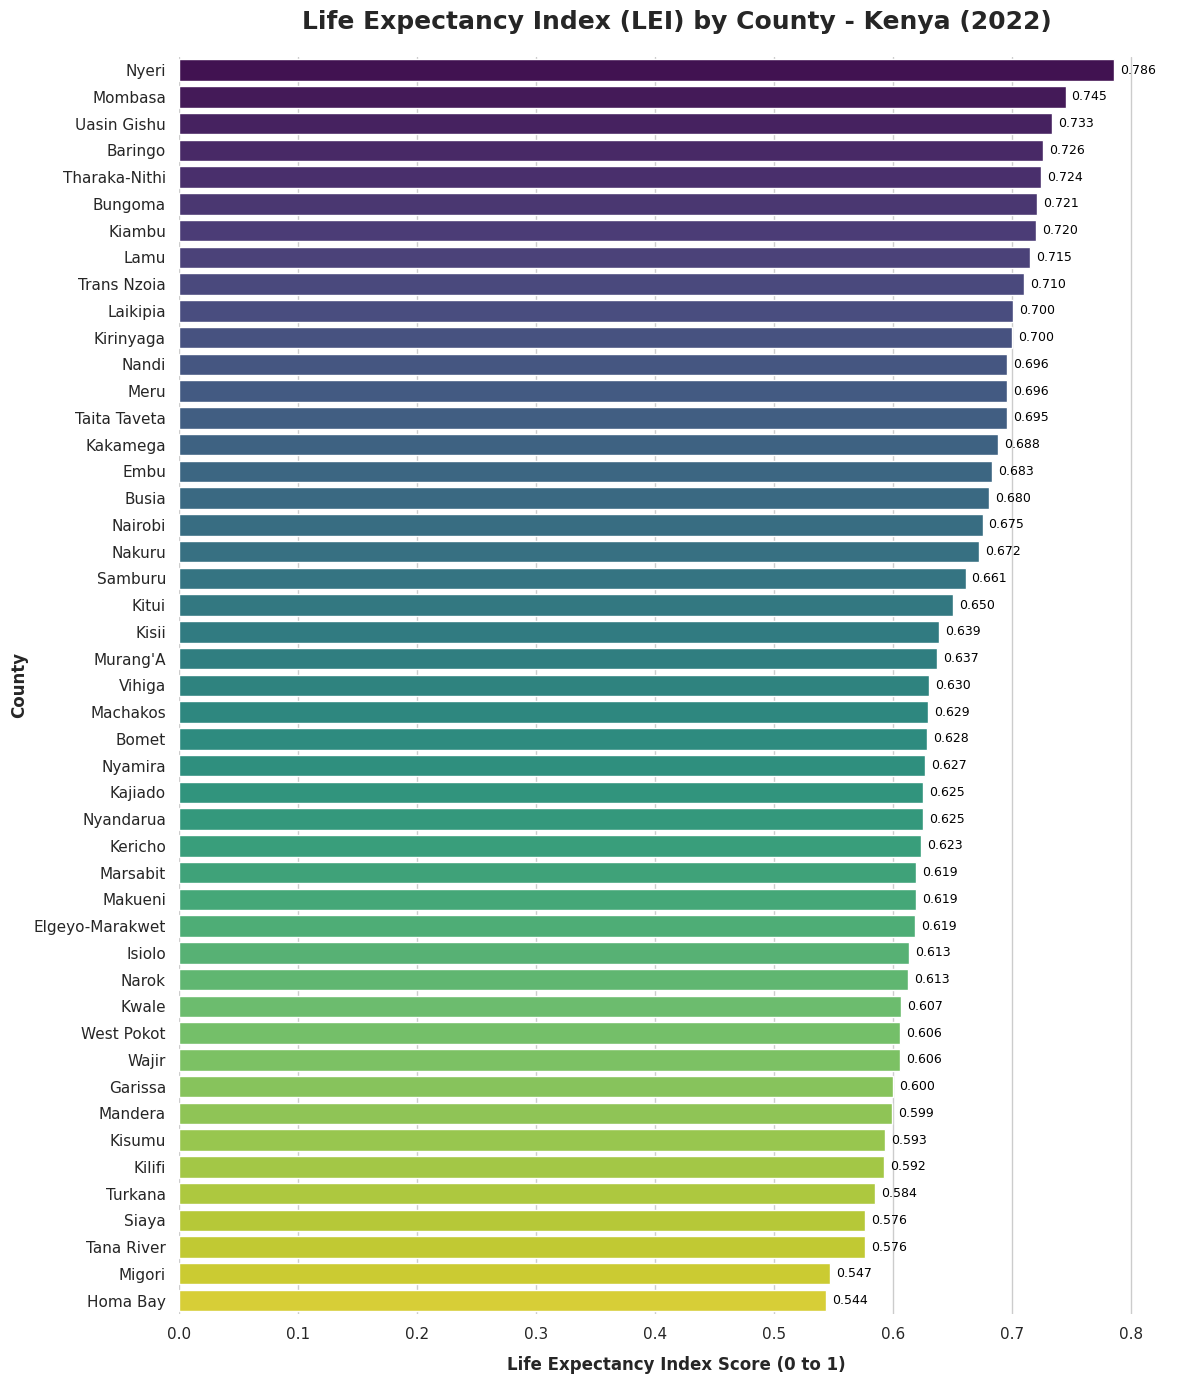

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming hdi_data is already loaded in your Kaggle environment
# 1. Clean and filter the data
# Exclude the national average ('Kenya') and drop rows with missing values in LEI
df_plot = hdi_data[hdi_data['County'] != 'Kenya'].copy()
df_plot = df_plot.dropna(subset=['County', 'LEI'])

# Capitalize county names for better presentation
df_plot['County'] = df_plot['County'].str.title()

# Sort the data from highest to lowest LEI
df_plot = df_plot.sort_values(by='LEI', ascending=False)

# 2. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 14)) # Tall figure to accommodate all 47 counties

# 3. Create a horizontal barplot
# Using a sequential color palette to highlight the highest values
ax = sns.barplot(
    x='LEI', 
    y='County', 
    data=df_plot, 
    palette="viridis", 
    hue='County',      # Assigning hue to x prevents a seaborn future warning
    legend=False
)

# 4. Add data labels to the end of each bar
for p in ax.patches:
    width = p.get_width()
    # Only label bars that actually have a width
    if width > 0: 
        ax.text(
            width + 0.005,       # Slightly offset to the right of the bar
            p.get_y() + p.get_height() / 2, # Center vertically
            f'{width:.3f}',      # Format to 3 decimal places
            ha='left', 
            va='center', 
            fontsize=9,
            color='black'
        )

# 5. Formatting the plot
plt.title("Life Expectancy Index (LEI) by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Life Expectancy Index Score (0 to 1)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

# Set x-axis limit slightly higher than the max value to make room for text labels
plt.xlim(0, df_plot['LEI'].max() + 0.05) 

# Remove the top and right spines for a cleaner look
sns.despine(left=True, bottom=True)

plt.tight_layout()

# 6. Save the plot as a downloadable high-resolution PNG file in Kaggle
# plt.savefig('kenya_lei_ranked.png', dpi=300, bbox_inches='tight')

plt.show()

### 3. Education Index by County

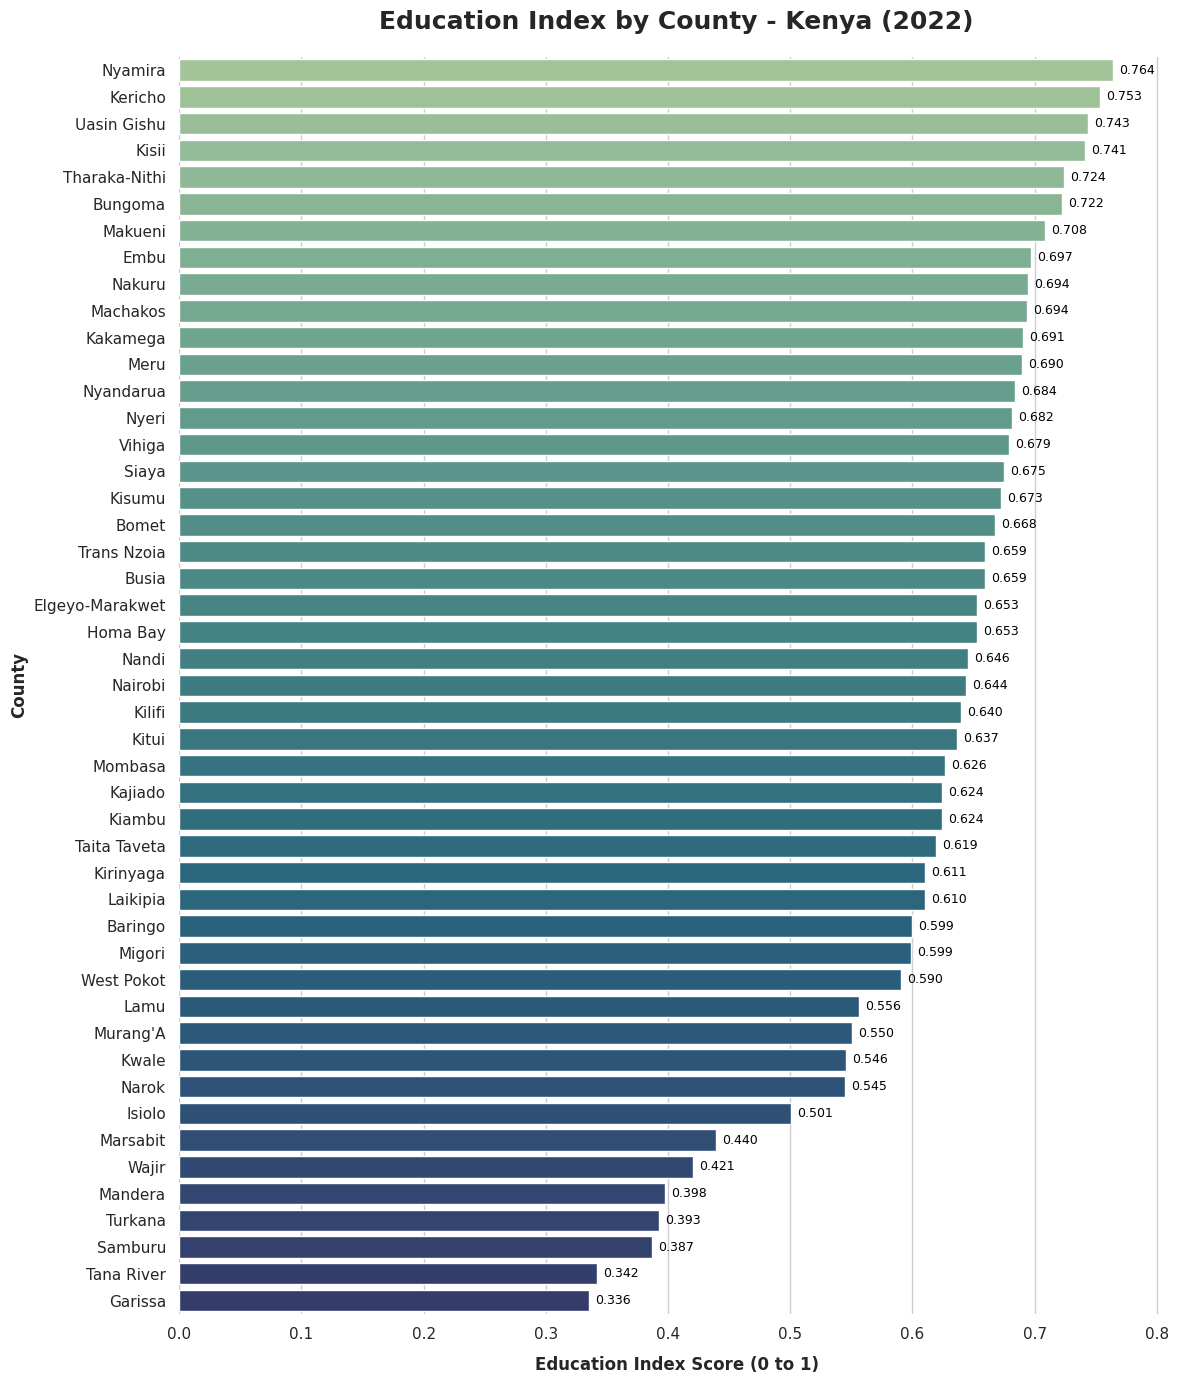

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean and filter the data for Education Index using the existing hdi_data dataframe
# Using 'Combined Edu I' which represents the Education Index
df_edu = hdi_data[hdi_data['County'] != 'Kenya'].copy()
df_edu = df_edu.dropna(subset=['County', 'Combined Edu I'])

df_edu['County'] = df_edu['County'].str.title()
df_edu = df_edu.sort_values(by='Combined Edu I', ascending=False)

# 2. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 14)) 

# 3. Create the horizontal barplot
ax = sns.barplot(
    x='Combined Edu I', 
    y='County', 
    data=df_edu, 
    palette="crest",  # Blue-green color palette fitting for education
    hue='County',      
    legend=False
)

# 4. Add data labels to the end of each bar
for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.text(
            width + 0.005,       
            p.get_y() + p.get_height() / 2, 
            f'{width:.3f}',      
            ha='left', 
            va='center', 
            fontsize=9,
            color='black'
        )

# 5. Formatting the plot
plt.title("Education Index by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Education Index Score (0 to 1)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

plt.xlim(0, df_edu['Combined Edu I'].max() + 0.05) 
sns.despine(left=True, bottom=True)
plt.tight_layout()

# 6. Save the plot as a downloadable high-resolution PNG file in Kaggle
# plt.savefig('kenya_education_index_ranked.png', dpi=300, bbox_inches='tight')

plt.show()

### 4. Gross National Income by County

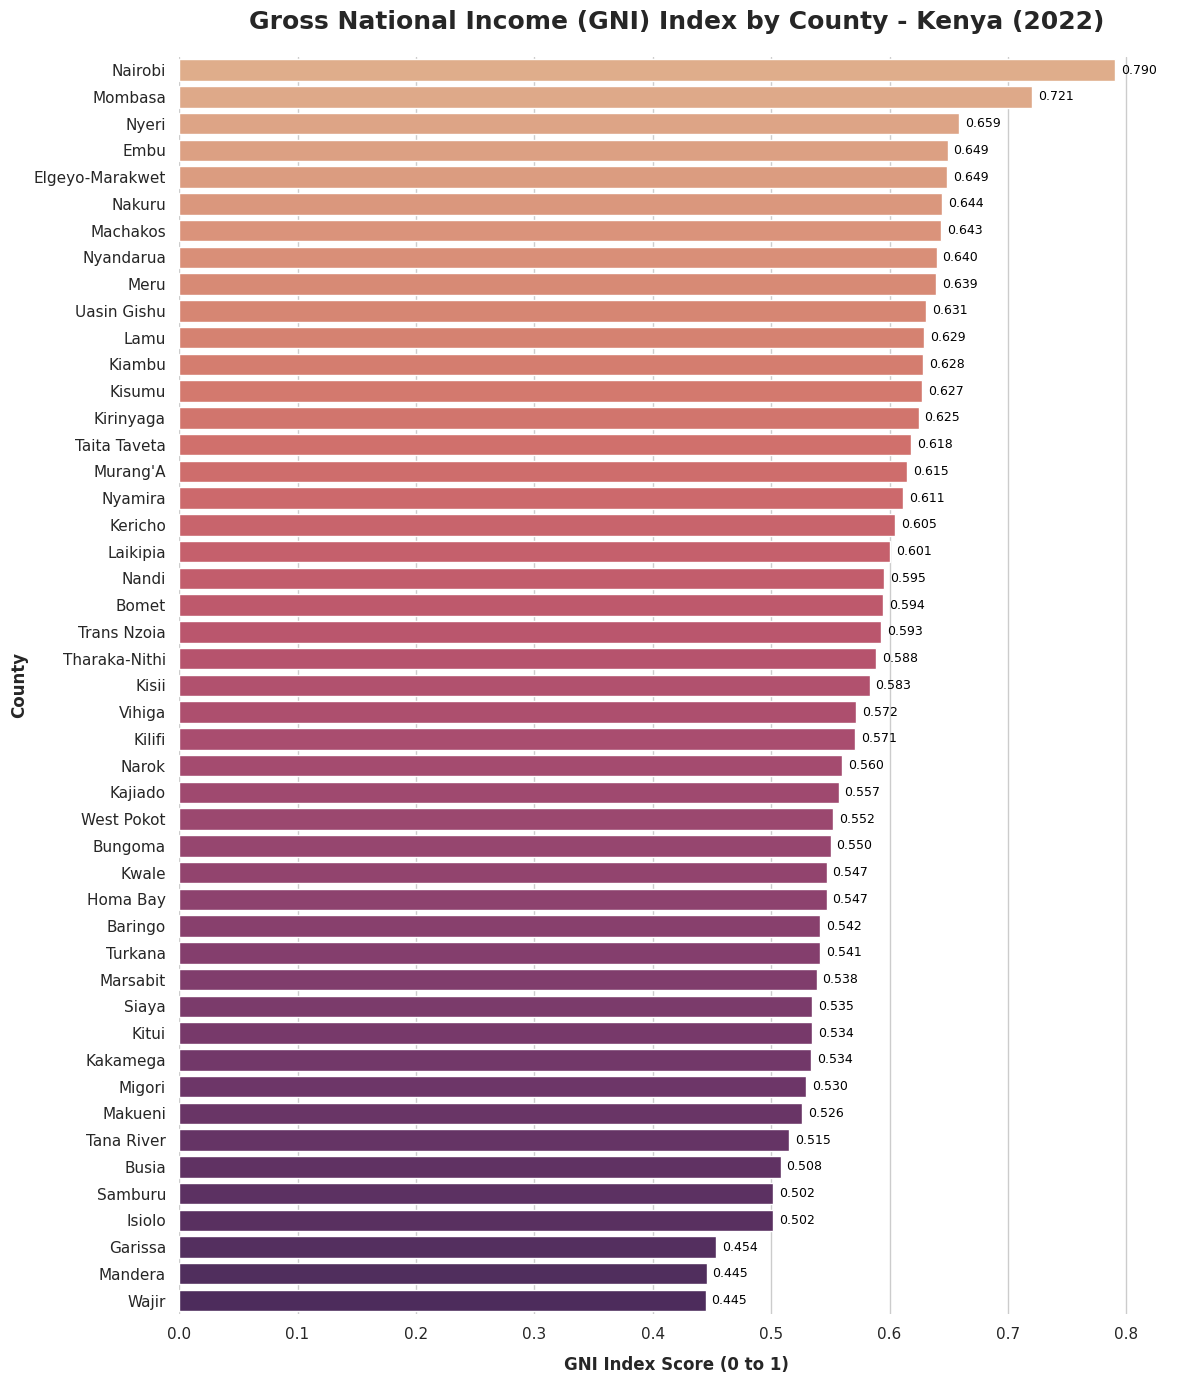

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean and filter the data for GNI Index using the existing hdi_data dataframe
df_gni = hdi_data[hdi_data['County'] != 'Kenya'].copy()
df_gni = df_gni.dropna(subset=['County', 'GNI Index'])

df_gni['County'] = df_gni['County'].str.title()
df_gni = df_gni.sort_values(by='GNI Index', ascending=False)

# 2. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 14)) 

# 3. Create the horizontal barplot
ax = sns.barplot(
    x='GNI Index', 
    y='County', 
    data=df_gni, 
    palette="flare",  # Warm color palette for income data 
    hue='County',      
    legend=False
)

# 4. Add data labels
for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.text(
            width + 0.005,       
            p.get_y() + p.get_height() / 2, 
            f'{width:.3f}',      
            ha='left', 
            va='center', 
            fontsize=9,
            color='black'
        )

# 5. Formatting
plt.title("Gross National Income (GNI) Index by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("GNI Index Score (0 to 1)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

plt.xlim(0, df_gni['GNI Index'].max() + 0.05) 
sns.despine(left=True, bottom=True)
plt.tight_layout()

# 6. Save and show
# plt.savefig('kenya_gni_index_ranked.png', dpi=300, bbox_inches='tight')
plt.show()

### 5. Overall HDI by County

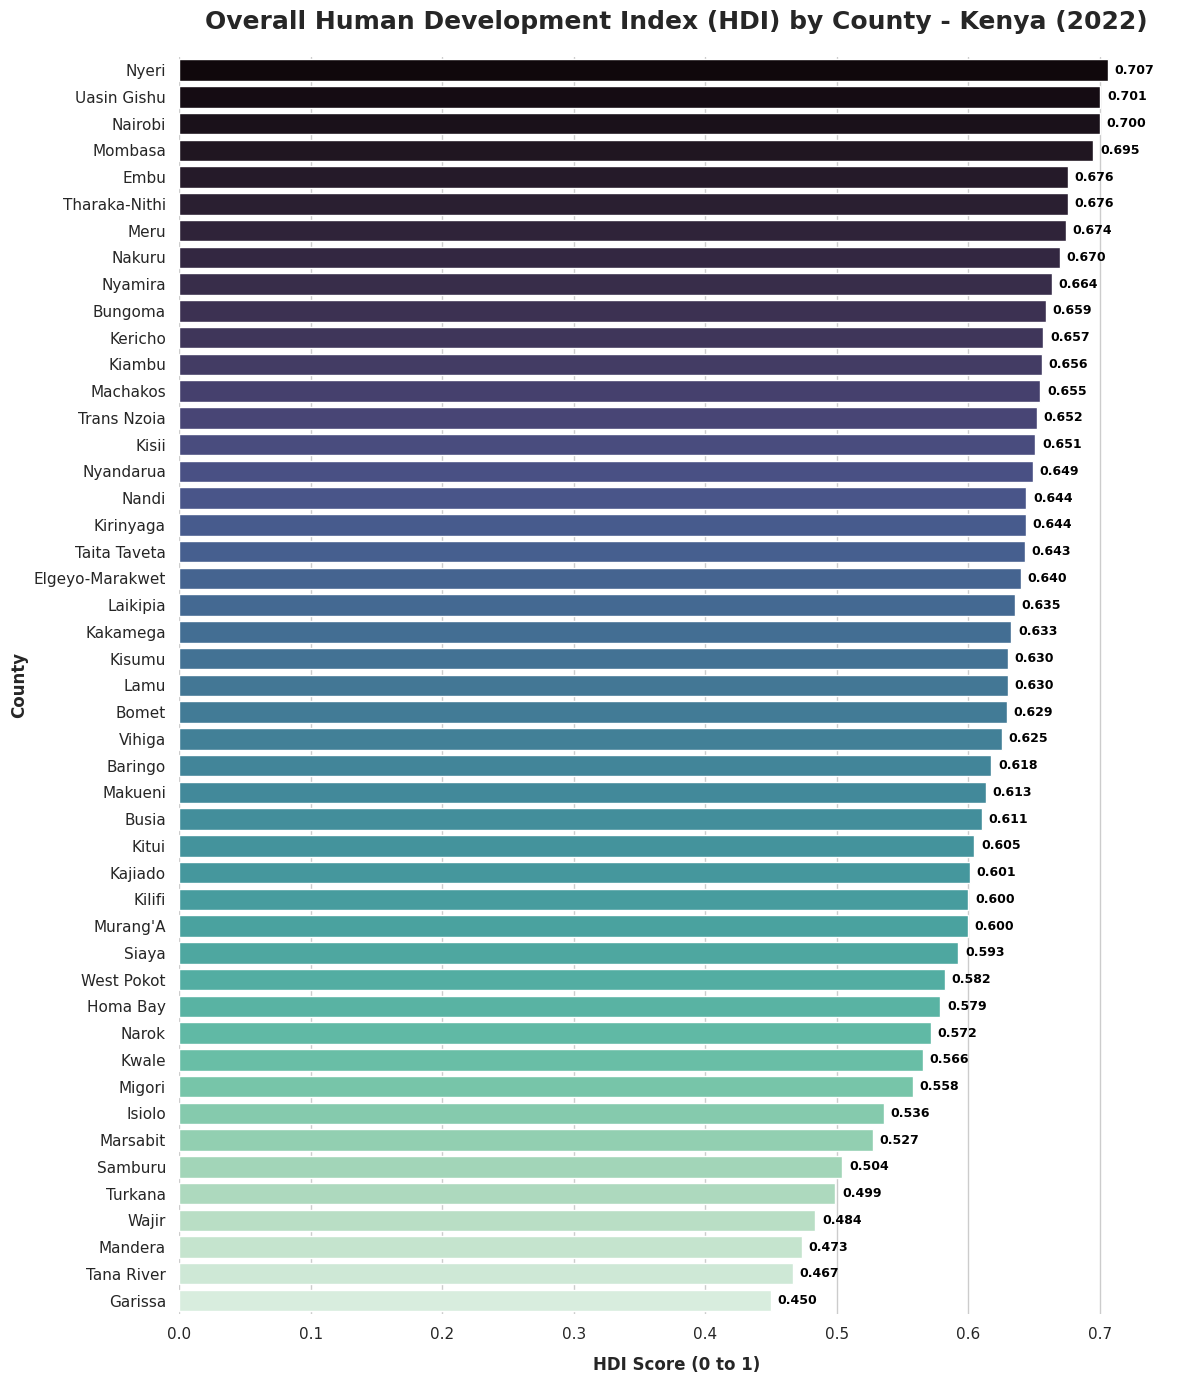

In [16]:
# Clean and filter for Overall HDI
df_overall = hdi_data[hdi_data['County'] != 'Kenya'].copy()
df_overall = df_overall.dropna(subset=['County', 'HDI_Score'])

df_overall['County'] = df_overall['County'].str.title()
df_overall = df_overall.sort_values(by='HDI_Score', ascending=False)

# Set up plot
plt.figure(figsize=(12, 14)) 

# Create barplot
ax = sns.barplot(
    x='HDI_Score', 
    y='County', 
    data=df_overall, 
    palette="mako",  # Deep blue palette for the aggregate HDI
    hue='County',      
    legend=False
)

# Add data labels
for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.text(
            width + 0.005,       
            p.get_y() + p.get_height() / 2, 
            f'{width:.3f}',      
            ha='left', 
            va='center', 
            fontsize=9,
            color='black',
            fontweight='bold'
        )

# Formatting
plt.title("Overall Human Development Index (HDI) by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("HDI Score (0 to 1)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

plt.xlim(0, df_overall['HDI_Score'].max() + 0.05) 
sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save and show
# plt.savefig('kenya_overall_hdi_ranked.png', dpi=300, bbox_inches='tight')
plt.show()

### 6. Scatter Diagram on Living Standards and Health

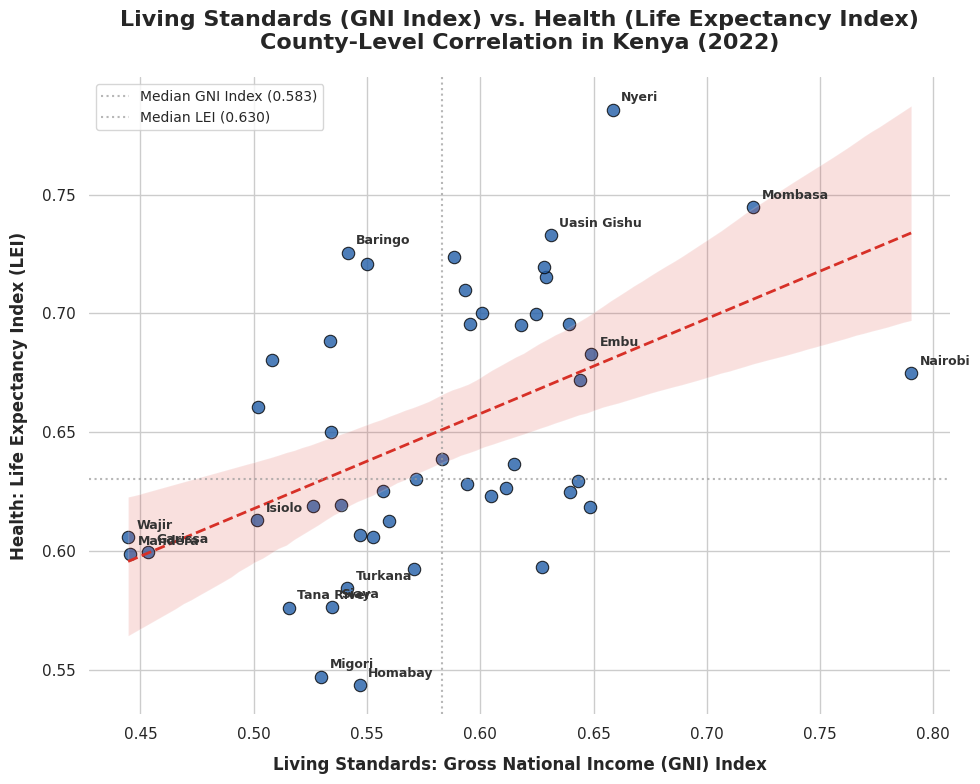

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load and Merge Datasets from existing notebook variables/files
# Load HDI / Indices data
xls_hdi = pd.ExcelFile("/kaggle/input/datasets/lekakeny/human-development-report/2026 HDI Revised.xlsx")
hdi_df = pd.read_excel(xls_hdi, sheet_name='HDI', header=1)
hdi_df = hdi_df.rename(columns={'Unnamed: 1': 'County'})
hdi_clean = hdi_df[hdi_df['County'] != 'Kenya'].copy()
hdi_clean['County'] = hdi_clean['County'].str.strip().str.title()

# 2. Set up Plotting Environment
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 8), facecolor='white')

# Extract variables: X = GNI Index (Living Standards), Y = LEI (Health)
x_var = hdi_clean['GNI Index']
y_var = hdi_clean['LEI']
counties = hdi_clean['County']

# 3. Create Scatter Plot with Regression Trendline
sns.regplot(
    x=x_var, 
    y=y_var, 
    data=hdi_clean,
    color='#225ea8',
    marker='o',
    scatter_kws={'s': 80, 'alpha': 0.8, 'edgecolors': 'black', 'linewidths': 0.8},
    line_kws={'color': '#d73027', 'linewidth': 2, 'linestyle': '--'},
    ax=ax
)

# 4. Add Smart Labeling for Extreme Outliers
# Calculate medians to identify quadrant extremes
x_median = x_var.median()
y_median = y_var.median()

for i, txt in enumerate(counties):
    x_val = x_var.iloc[i]
    y_val = y_var.iloc[i]
    
    # Label counties that are extreme outliers (top/bottom performers in either metric)
    if x_val > x_var.quantile(0.92) or x_val < x_var.quantile(0.08) or \
       y_val > y_var.quantile(0.92) or y_val < y_var.quantile(0.08) or txt in ['Nairobi', 'Turkana', 'Mombasa']:
        ax.annotate(
            txt, 
            (x_val, y_val),
            xytext=(6, 6), 
            textcoords='offset points',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

# 5. Formatting & Quadrant Reference Lines
ax.axvline(x_median, color='#999999', linestyle=':', alpha=0.7, label=f'Median GNI Index ({x_median:.3f})')
ax.axhline(y_median, color='#999999', linestyle=':', alpha=0.7, label=f'Median LEI ({y_median:.3f})')

ax.set_title("Living Standards (GNI Index) vs. Health (Life Expectancy Index)\nCounty-Level Correlation in Kenya (2022)", 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel("Living Standards: Gross National Income (GNI) Index", fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel("Health: Life Expectancy Index (LEI)", fontsize=12, fontweight='bold', labelpad=10)

ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#cccccc', fontsize=10)
sns.despine(left=True, bottom=True)

plt.tight_layout()

# 6. Save the figure
# plt.savefig('kenya_living_standards_vs_health_scatter.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### 7. Correlation between Living Standards (GNI Index) and Education (Combined Education Index)

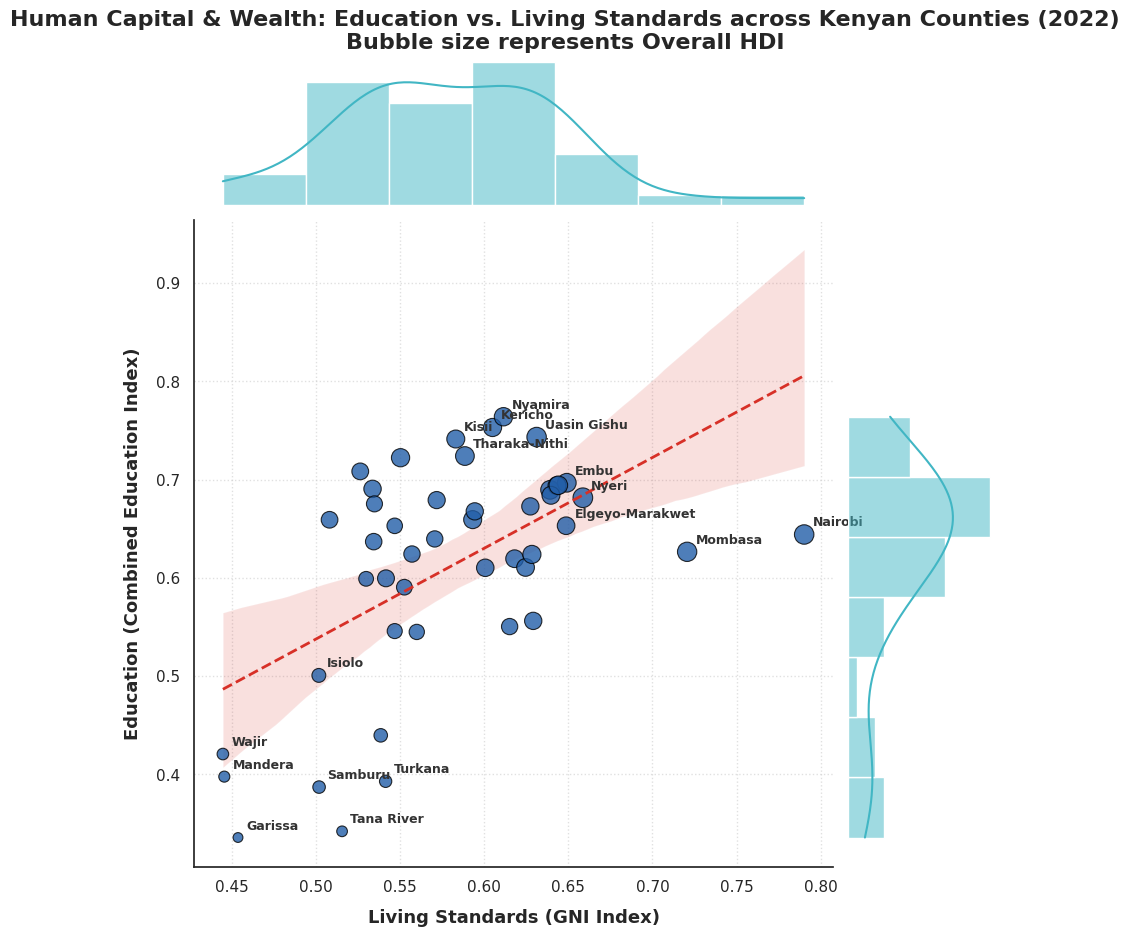

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Updated Data
# Using the newly provided dataset verbatim
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/inequality-adjusted-human-development-index/2026 IHDI_revised.xlsx")
hdi_df = pd.read_excel(xls, sheet_name='HDI', header=1)

# Clean and extract relevant columns
hdi_df = hdi_df.rename(columns={'Unnamed: 1': 'County'})
hdi_clean = hdi_df[~hdi_df['County'].astype(str).str.contains("Kenya|NaN", na=False, case=False)].copy()
hdi_clean['County'] = hdi_clean['County'].str.strip().str.title()
hdi_clean = hdi_clean.dropna(subset=['GNI Index', 'Combined Edu I', 'HDI'])

# 2. Set up the Jointplot framework
sns.set_theme(style="white")

# Create a JointGrid for maximum customization
g = sns.JointGrid(
    data=hdi_clean, 
    x='GNI Index', 
    y='Combined Edu I',
    height=9,
    ratio=4,  # Ratio of joint axes size to marginal axes height
    space=0.1 # Space between central plot and margins
)

# 3. Plot the Central Bivariate Scatter and Trendline
# Plot the regression line first so it sits behind the points
sns.regplot(
    data=hdi_clean,
    x='GNI Index',
    y='Combined Edu I',
    scatter=False,
    color='#d73027', 
    line_kws={'linewidth': 2, 'linestyle': '--'},
    ax=g.ax_joint
)

# Plot the scatter points, sizing them slightly by their overall HDI
sns.scatterplot(
    data=hdi_clean,
    x='GNI Index',
    y='Combined Edu I',
    size='HDI',
    sizes=(50, 200),
    color='#225ea8',
    alpha=0.8,
    edgecolor='black',
    linewidth=0.8,
    legend=False,
    ax=g.ax_joint
)

# 4. Plot the Marginal Distributions (Top and Right)
# Top Margin: Distribution of GNI Index
sns.histplot(
    data=hdi_clean,
    x='GNI Index',
    fill=True,
    color='#41b6c4',
    kde=True,
    linewidth=1,
    ax=g.ax_marg_x
)

# Right Margin: Distribution of Education Index
sns.histplot(
    data=hdi_clean,
    y='Combined Edu I',
    fill=True,
    color='#41b6c4',
    kde=True,
    linewidth=1,
    ax=g.ax_marg_y
)

# Remove the marginal axes labels/spines for a cleaner look
g.ax_marg_x.set_axis_off()
g.ax_marg_y.set_axis_off()

# 5. Add Smart Labeling for Key Counties
x_var = hdi_clean['GNI Index']
y_var = hdi_clean['Combined Edu I']

for i, row in hdi_clean.iterrows():
    x_val = row['GNI Index']
    y_val = row['Combined Edu I']
    txt = row['County']
    
    # Label extreme outliers (top 10% or bottom 10% in either metric) or key cities
    if x_val > x_var.quantile(0.90) or x_val < x_var.quantile(0.10) or \
       y_val > y_var.quantile(0.90) or y_val < y_var.quantile(0.10) or txt in ['Nairobi', 'Turkana', 'Mombasa']:
        g.ax_joint.annotate(
            txt, 
            (x_val, y_val),
            xytext=(6, 6), 
            textcoords='offset points',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

# 6. Formatting & Customization
g.ax_joint.set_xlabel("Living Standards (GNI Index)", fontsize=13, fontweight='bold', labelpad=10)
g.ax_joint.set_ylabel("Education (Combined Education Index)", fontsize=13, fontweight='bold', labelpad=10)

# Add gridlines to the central plot
g.ax_joint.grid(True, linestyle=':', alpha=0.6)

# Main Title 
plt.suptitle(
    "Human Capital & Wealth: Education vs. Living Standards across Kenyan Counties (2022)\n"
    "Bubble size represents Overall HDI", 
    fontsize=16, 
    fontweight='bold', 
    y=1.03
)

# 7. Save the figure
# plt.savefig('kenya_living_standards_vs_education_jointplot.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## Inequality Adjusted Human Development Index (IHDI)
### 1. National IHDI with Dimensions

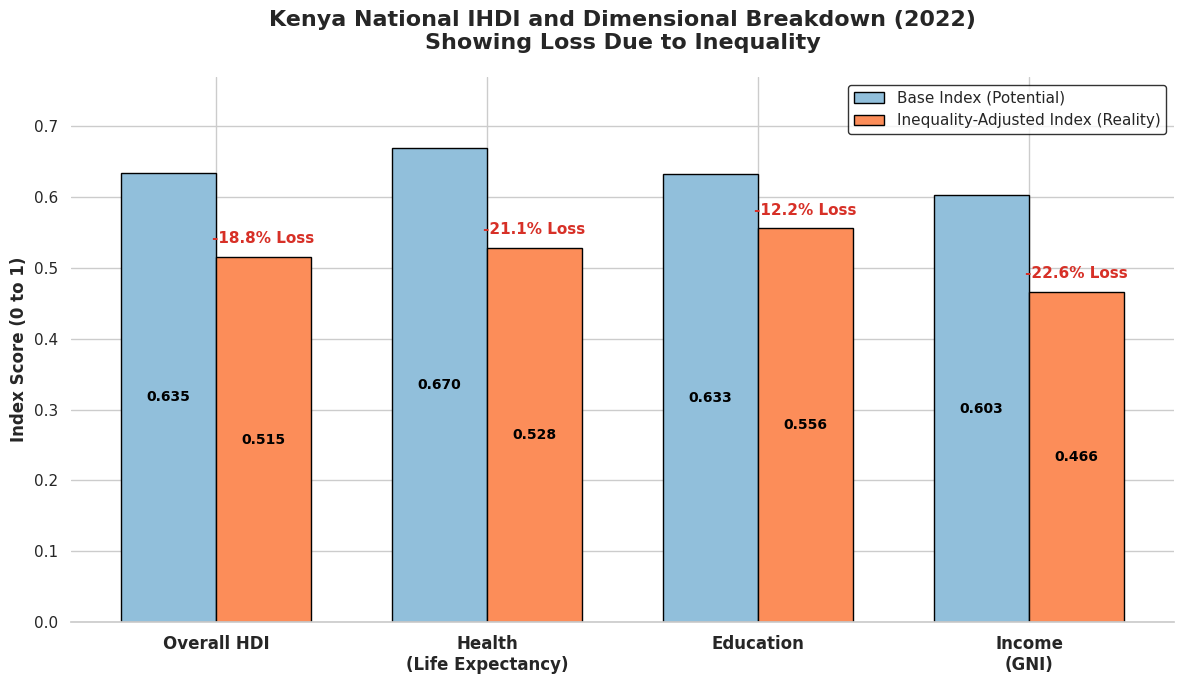

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/inequality-adjusted-human-development-index/2026 IHDI_revised.xlsx")
# Read the first sheet, using row 1 as the header
df = pd.read_excel(xls, sheet_name=0, header=1) 

# Extract the national row for Kenya
kenya = df[df.iloc[:, 1].astype(str).str.contains("Kenya", na=False, case=False)].iloc[0]

# 2. Extract Data for the 4 Categories
categories = ['Overall HDI', 'Health\n(Life Expectancy)', 'Education', 'Income\n(GNI)']

# Base Indices
base_scores = [
    kenya['HDI using logged income'],
    kenya['Life Expec index'],
    kenya['Combined yrs of sch Index'],
    kenya['GNI index with logged GNI_GCP']
]

# Inequality-Adjusted Indices
adjusted_scores = [
    kenya['IHDI assuming Income dist  for average and logged income is same'],
    kenya['Inequality Adjusted for life index = (1-A)*LE index'],
    kenya['Inequality adjustedindex for Edu'],
    # The income adjusted index is derived from the base index and the income loss %
    kenya['GNI index with logged GNI_GCP'] * (1 - (kenya['Loss due to inequality in income (%)'] / 100))
]

# Percentage Losses
losses = [
    kenya['Loss of human development due to Inequality,  (using logged incomes (%)'],
    kenya['Loss due to Life expectancy'],
    kenya['Loss due to inequality in edu'],
    kenya['Loss due to inequality in income (%)']
]

# 3. Plotting Setup
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(categories))
width = 0.35  # Width of the bars

# Create the paired bars
bars1 = ax.bar(x - width/2, base_scores, width, label='Base Index (Potential)', color='#91bfdb', edgecolor='black')
bars2 = ax.bar(x + width/2, adjusted_scores, width, label='Inequality-Adjusted Index (Reality)', color='#fc8d59', edgecolor='black')

# 4. Annotations
for i in range(len(categories)):
    # Annotate the specific percentage loss directly above the adjusted bar
    ax.text(
        x[i] + width/2, 
        adjusted_scores[i] + 0.015, 
        f'-{losses[i]:.1f}% Loss', 
        ha='center', 
        va='bottom', 
        fontweight='bold', 
        color='#d73027', 
        fontsize=11
    )
    
    # Annotate the raw index score inside the base bar
    ax.text(
        x[i] - width/2, 
        base_scores[i] / 2, 
        f'{base_scores[i]:.3f}', 
        ha='center', 
        va='center', 
        color='black', 
        fontsize=10,
        fontweight='bold'
    )
    
    # Annotate the raw adjusted score inside the adjusted bar
    ax.text(
        x[i] + width/2, 
        adjusted_scores[i] / 2, 
        f'{adjusted_scores[i]:.3f}', 
        ha='center', 
        va='center', 
        color='black', 
        fontsize=10,
        fontweight='bold'
    )

# 5. Formatting the Plot
ax.set_title("Kenya National IHDI and Dimensional Breakdown (2022)\nShowing Loss Due to Inequality", fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel("Index Score (0 to 1)", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')

# Expand y-axis slightly to make room for the loss annotations
ax.set_ylim(0, max(base_scores) + 0.1)

# Add a prominent legend
ax.legend(loc='upper right', fontsize=11, frameon=True, facecolor='white', edgecolor='black')

sns.despine(left=True)
plt.tight_layout()

# 6. Save the graphic for your report
# plt.savefig('kenya_national_ihdi_breakdown.png', dpi=300, bbox_inches='tight')
plt.show()

### 2. IHDI by County

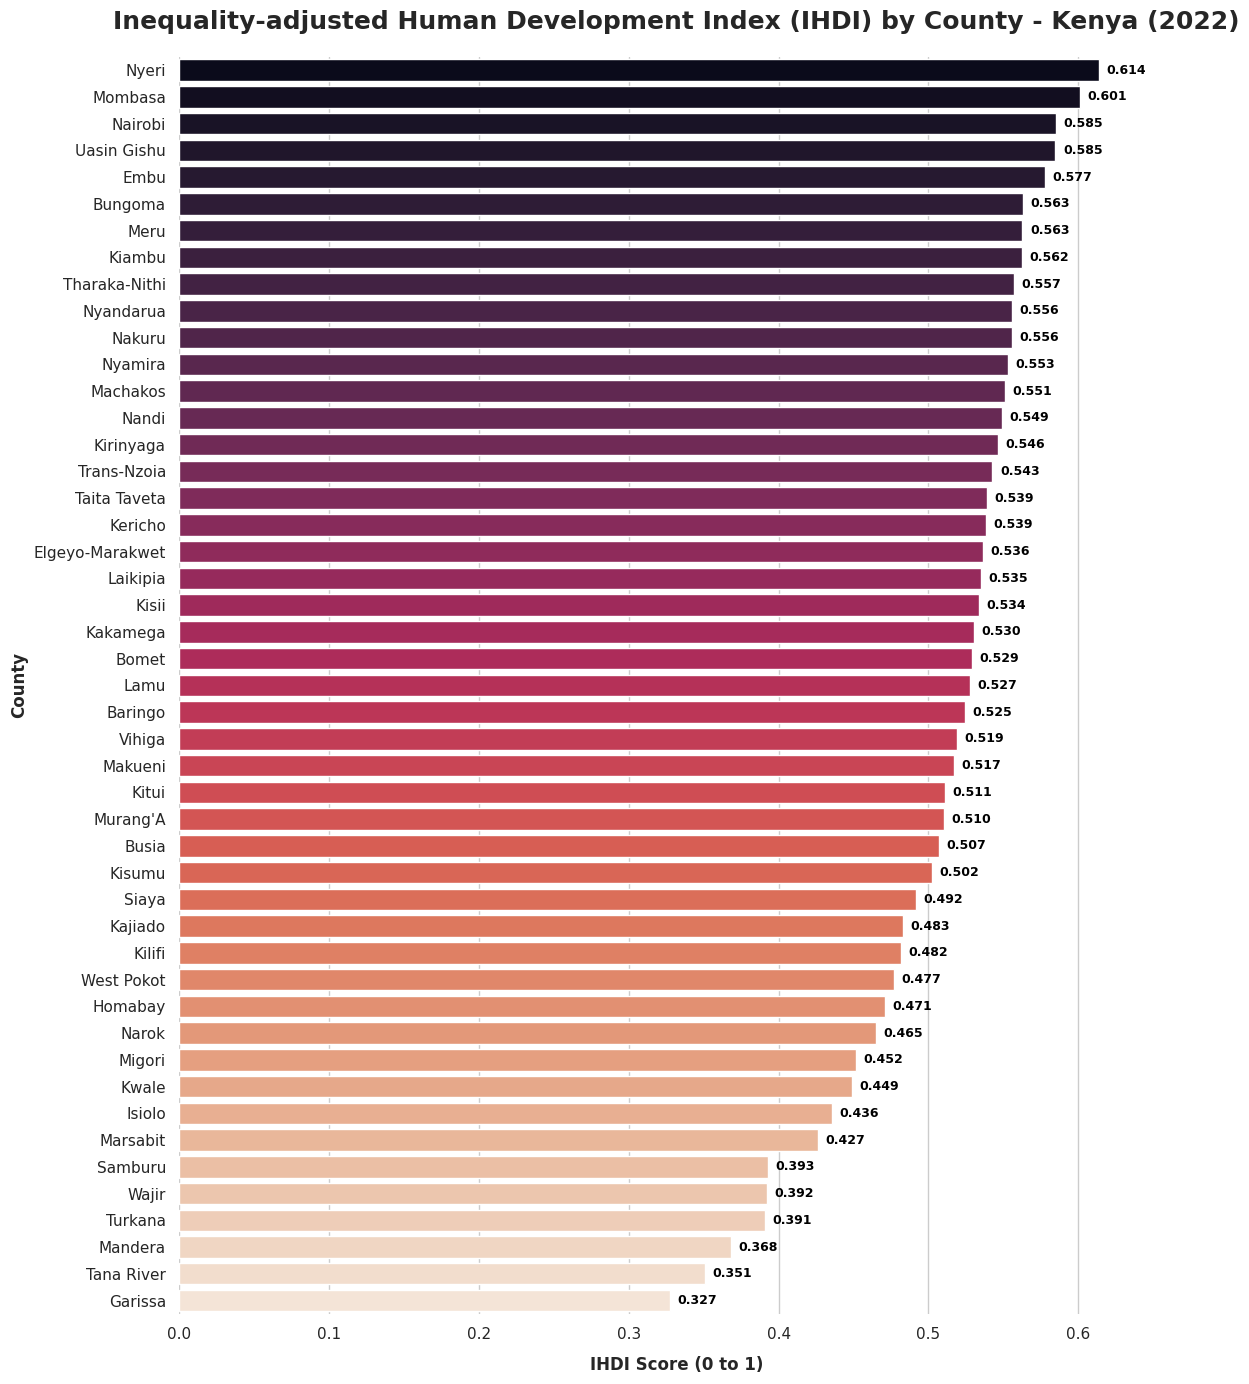

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/inequality-adjusted-human-development-index/2026 IHDI_revised.xlsx")
# Read the first sheet, using row 1 as the header
df = pd.read_excel(xls, sheet_name=0, header=1) 

# Rename columns for easier access
df = df.rename(columns={
    'Unnamed: 1': 'County', 
    'IHDI assuming Income dist  for average and logged income is same': 'IHDI'
})

# 2. Clean and Filter the Data
# Exclude the national row ('Kenya') and drop any empty rows
df_ihdi = df[~df['County'].astype(str).str.contains("Kenya", na=False, case=False)].copy()
df_ihdi = df_ihdi.dropna(subset=['County', 'IHDI'])

# Format county names to Title Case for a professional look
df_ihdi['County'] = df_ihdi['County'].astype(str).str.strip().str.title()

# Sort the data from highest to lowest IHDI
df_ihdi = df_ihdi.sort_values(by='IHDI', ascending=False)

# 3. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 14)) # Tall figure to accommodate all 47 counties

# 4. Create the horizontal barplot
# Using the 'rocket' palette (dark purple to bright orange/pink) for a striking contrast 
ax = sns.barplot(
    x='IHDI', 
    y='County', 
    data=df_ihdi, 
    palette="rocket", 
    hue='County',      
    legend=False
)

# 5. Add data labels to the end of each bar
for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.text(
            width + 0.005,       # Slight offset to the right of the bar
            p.get_y() + p.get_height() / 2, # Center vertically
            f'{width:.3f}',      # Format to 3 decimal places
            ha='left', 
            va='center', 
            fontsize=9,
            color='black',
            fontweight='bold'
        )

# 6. Formatting the plot
plt.title("Inequality-adjusted Human Development Index (IHDI) by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("IHDI Score (0 to 1)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

# Set x-axis limit slightly higher than the max value to make room for text labels
plt.xlim(0, df_ihdi['IHDI'].max() + 0.05) 

# Remove the top and right spines for a cleaner look
sns.despine(left=True, bottom=True)

plt.tight_layout()

# 7. Save the plot as a downloadable high-resolution PNG file in Kaggle
plt.savefig('kenya_ihdi_by_county_ranked.png', dpi=300, bbox_inches='tight')

plt.show()

### 3. Overall Loss due to Inequality - by County

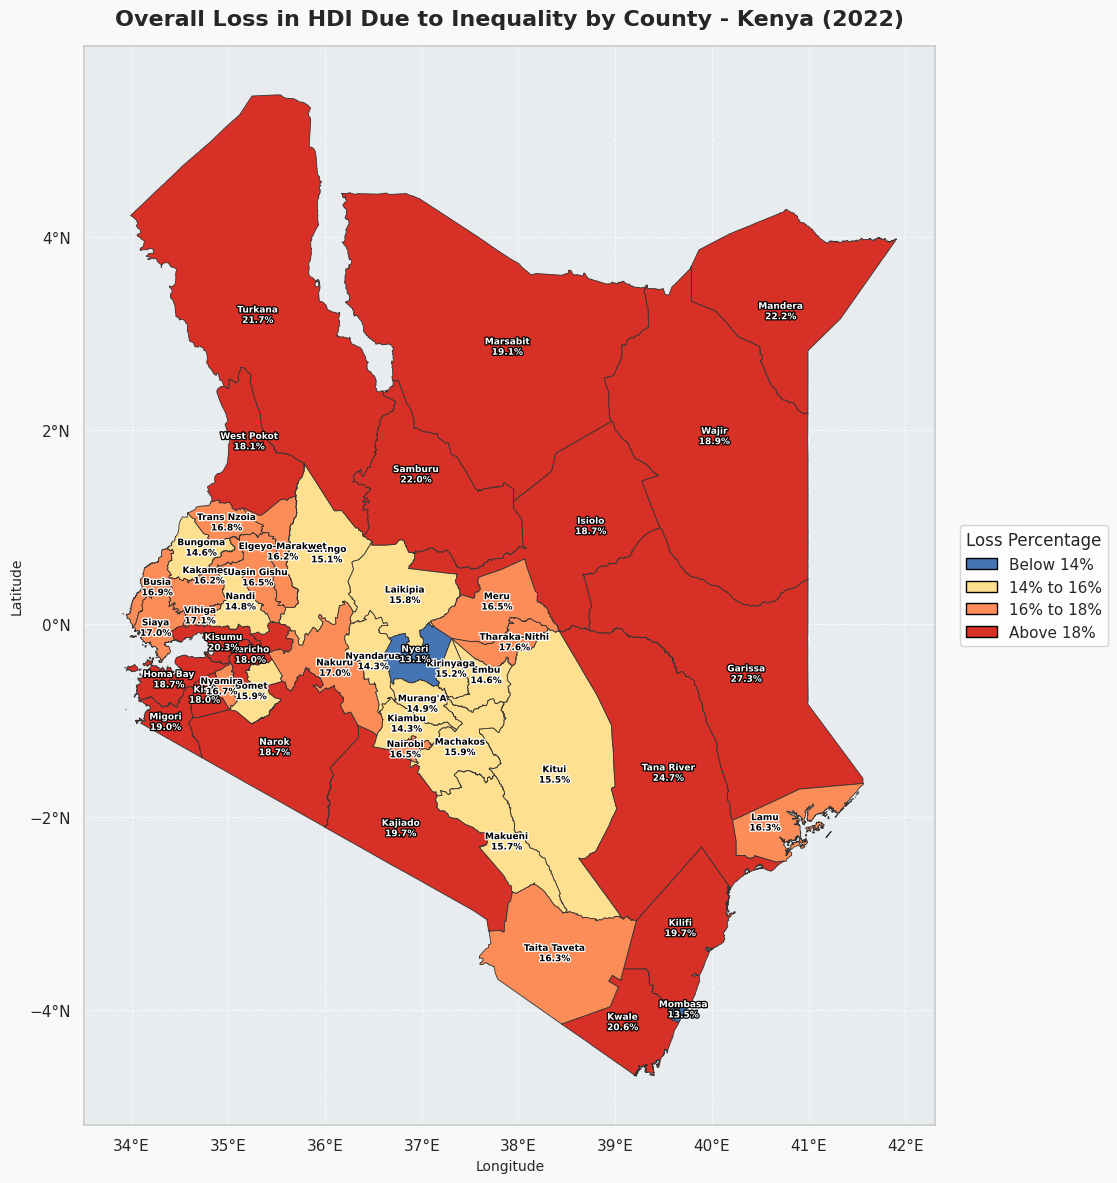

In [21]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patheffects as path_effects
import numpy as np

# 1. Load Geospatial Data
# Replace with your actual shapefile path
gdf = gpd.read_file('/kaggle/input/datasets/lekakeny/kenya-counties-map/ke_county.shp') 
gdf['County_Name'] = gdf['county'].str.strip().str.title()

# 2. Load IHDI Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/inequality-adjusted-human-development-index/2026 IHDI_revised.xlsx")
ihdi_data = pd.read_excel(xls, sheet_name=0, header=1)

# Rename the relevant columns
loss_col = 'Loss of human development due to Inequality,  (using logged incomes (%)'
ihdi_data = ihdi_data.rename(columns={
    'Unnamed: 1': 'County', 
    loss_col: 'Overall_Loss'
})

# Filter out national data and drop NaNs
ihdi_data = ihdi_data[~ihdi_data['County'].astype(str).str.contains("Kenya", na=False, case=False)].copy()
ihdi_data = ihdi_data.dropna(subset=['County', 'Overall_Loss'])

# # Rename Counties to match between the two datasets
ihdi_data.at[44, 'County'] = "Homa Bay"
ihdi_data.at[27, 'County'] = "Trans Nzoia"

ihdi_data['County'] = ihdi_data['County'].astype(str).str.strip().str.title()

# 3. Merge Geospatial and IHDI Data
map_data = gdf.merge(ihdi_data, left_on='County_Name', right_on='County', how='left')

# 4. Categorize Loss Values (4 active bins)
# Bins: <14%, 14-16%, 16-18%, >18%
bins = [0.0, 14.0, 16.0, 18.0, 100.0]
labels = ['Below 14%', '14% to 16%', '16% to 18%', 'Above 18%']

map_data['Loss_Category'] = pd.cut(map_data['Overall_Loss'], bins=bins, labels=labels, right=False)

# Color palette: Blue (Low Loss) to Red (High Loss)
color_mapping = {
    'Below 14%': '#4575b4',  # Deep Blue (Best / Lowest Loss)
    '14% to 16%': '#fee090', # Warm Light Yellow 
    '16% to 18%': '#fc8d59', # Orange 
    'Above 18%': '#d73027'   # Soft Red (Worst / Highest Loss)
}

# Assign colors. Fill unmatched counties with a neutral gray.
map_data['Color'] = map_data['Loss_Category'].map(color_mapping)

# 5. Plotting Setup
fig, ax = plt.subplots(1, 1, figsize=(12, 12), facecolor='#f8f9fa')
ax.set_facecolor('#e9ecef')

# Plot base map
map_data.plot(
    ax=ax, 
    color=map_data['Color'], 
    edgecolor='#333333', 
    linewidth=0.6
)



# 6. Add Enhanced County Labels & Values
for idx, row in map_data.iterrows():
    if pd.notna(row['Overall_Loss']):
        # Format label to show County Name and Loss Percentage
        label_text = f"{row['County']}\n{row['Overall_Loss']:.1f}%"
        
        # Guarantee the point is inside the county polygon
        point = row['geometry'].representative_point()
        x, y = point.x, point.y
        
        # Determine text color dynamically based on background contrast
        category = str(row['Loss_Category'])
        text_color = 'white' if category in ['Below 14%', 'Above 18%'] else 'black'
        stroke_color = 'black' if text_color == 'white' else 'white'

        txt = ax.annotate(
            text=label_text, 
            xy=(x, y), 
            fontsize=6.5, 
            ha='center', 
            va='center',
            color=text_color,
            weight='bold'
        )
        
        # Add stroke/halo effect around text so it pops
        txt.set_path_effects([
            path_effects.withStroke(linewidth=1.8, foreground=stroke_color)
        ])

# 7. Formatting & Legend
plt.title("Overall Loss in HDI Due to Inequality by County - Kenya (2022)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Longitude", fontsize=10)
plt.ylabel("Latitude", fontsize=10)

# Create legend 
legend_elements = [
    Patch(facecolor=color_mapping[label], edgecolor='black', label=label) 
    for label in labels
]

ax.legend(
    handles=legend_elements, 
    loc='center left', 
    bbox_to_anchor=(1.02, 0.5), 
    title="Loss Percentage",
    frameon=True,
    facecolor='white'
)

ax.grid(True, color='white', linestyle='--', linewidth=0.8, alpha=0.7)
ax.xaxis.set_major_formatter('{x:1.0f}°E')
ax.yaxis.set_major_formatter('{x:1.0f}°N')

plt.tight_layout()

# 8. Save the figure to Kaggle working directory
# plt.savefig('kenya_ihdi_loss_map.png', dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())

plt.show()

### 4. Breakdown of HDI Loss due to Inequality in Life Expectancy, Education and Income

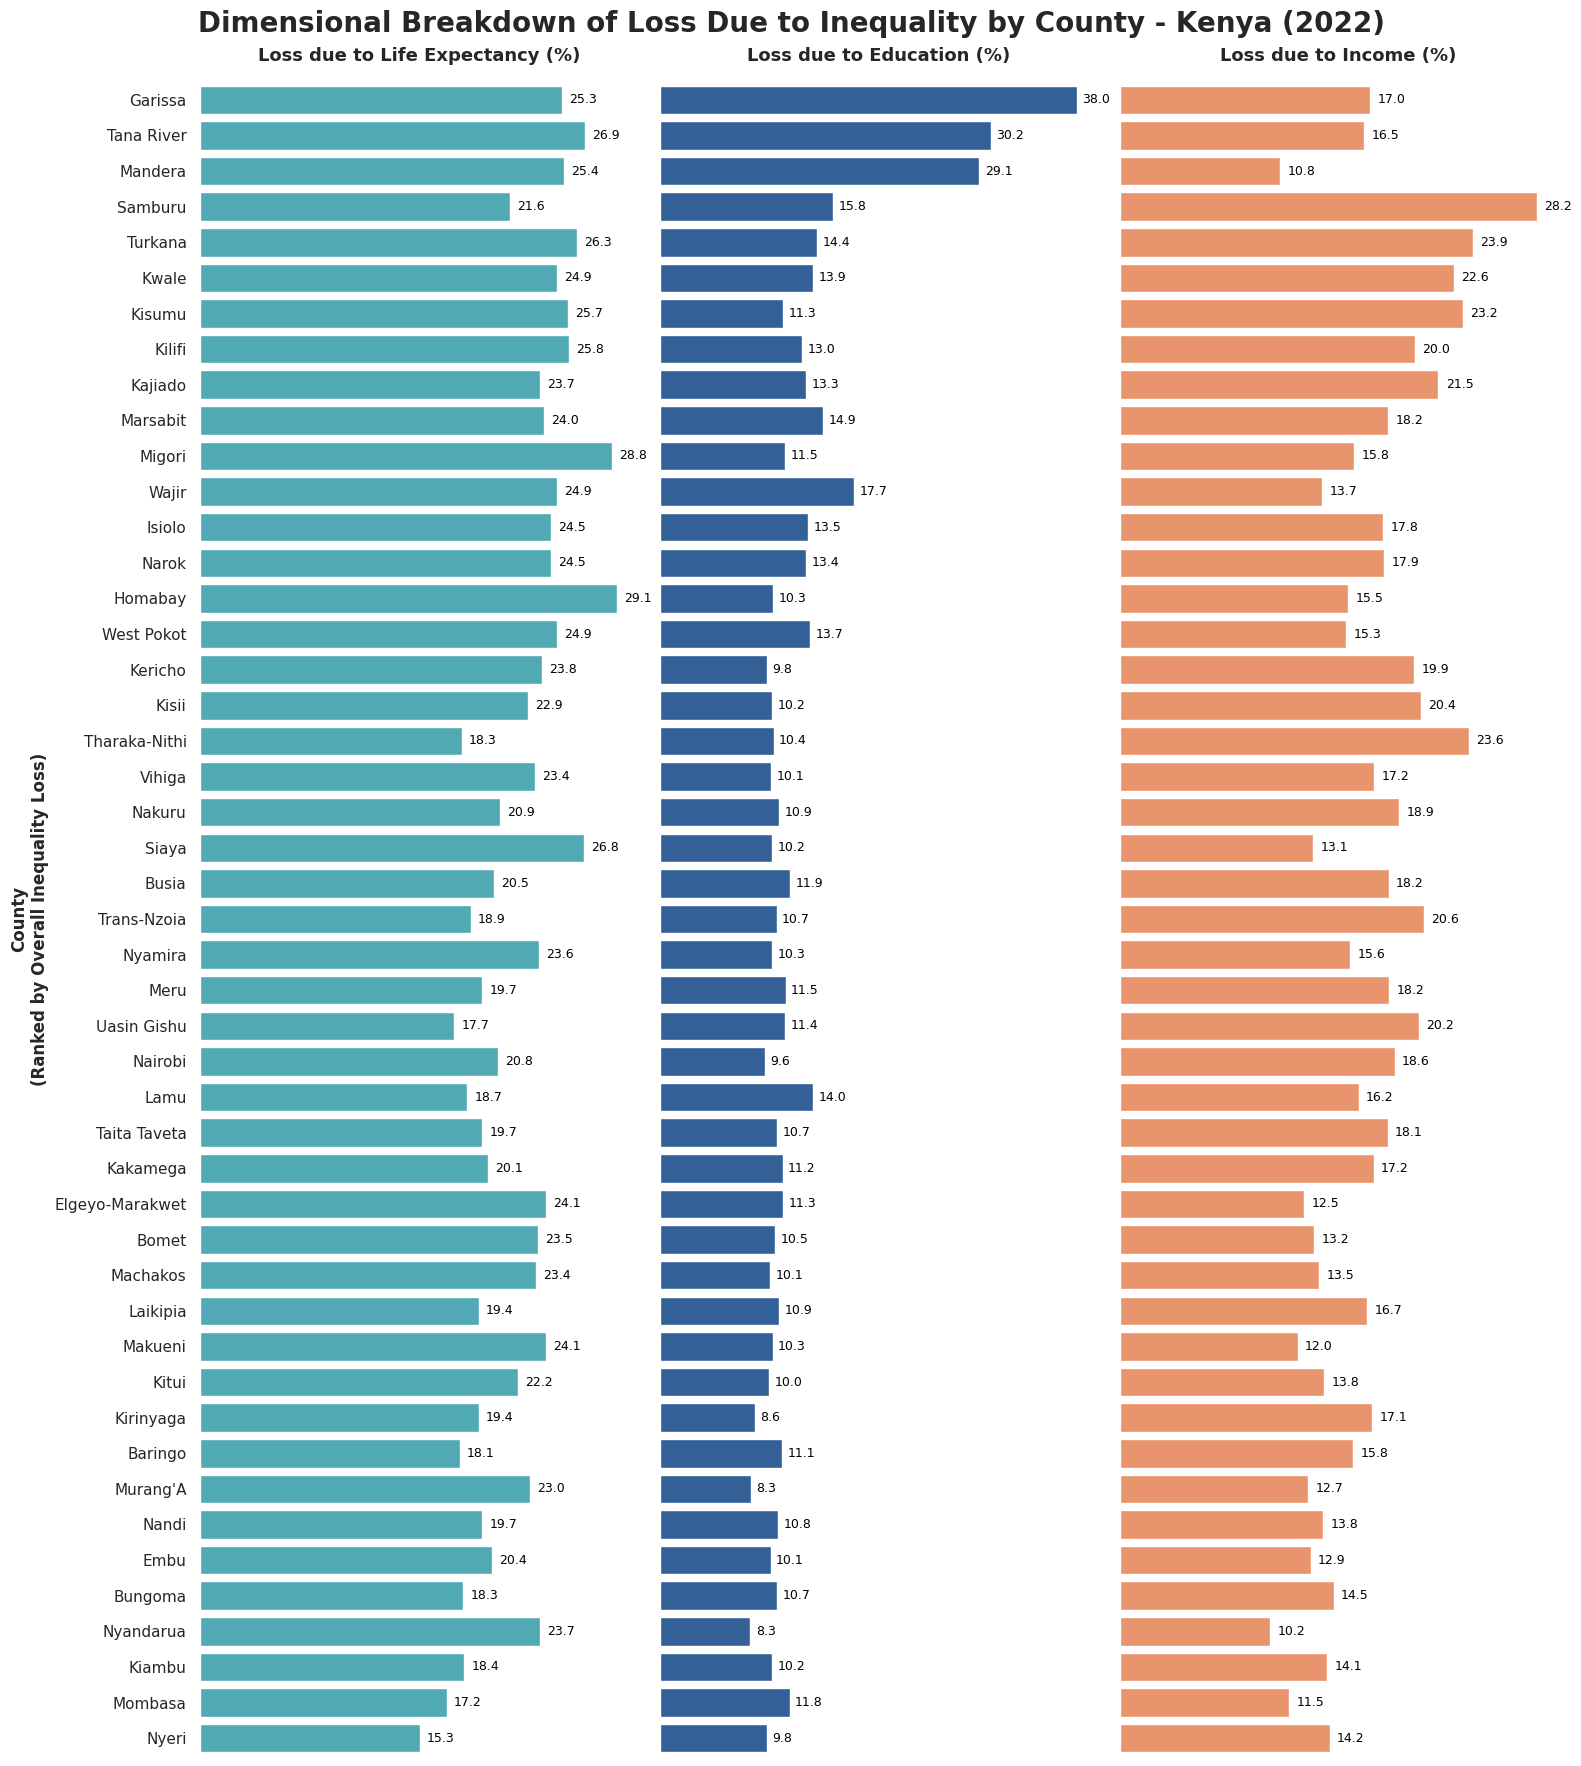

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/inequality-adjusted-human-development-index/2026 IHDI_revised.xlsx")
df = pd.read_excel(xls, sheet_name=0, header=1) 

# Define exact column names based on the dataset
col_county = 'Unnamed: 1'
col_loss_health = 'Loss due to Life expectancy'
col_loss_edu = 'Loss due to inequality in edu'
col_loss_inc = 'Loss due to inequality in income (%)'
col_loss_overall = 'Loss of human development due to Inequality,  (using logged incomes (%)'

# 2. Clean and Filter the Data
# Exclude the national row ('Kenya') and drop empty rows
df_loss = df[~df[col_county].astype(str).str.contains("Kenya", na=False, case=False)].copy()
df_loss = df_loss.dropna(subset=[col_county, col_loss_health, col_loss_edu, col_loss_inc])

# Format county names to Title Case
df_loss['County'] = df_loss[col_county].astype(str).str.strip().str.title()

# Convert loss columns to numeric (just in case)
for col in [col_loss_health, col_loss_edu, col_loss_inc, col_loss_overall]:
    df_loss[col] = pd.to_numeric(df_loss[col], errors='coerce')

# Sort by Overall Loss (Descending) so the most unequal counties are at the top
df_loss = df_loss.sort_values(by=col_loss_overall, ascending=False).reset_index(drop=True)

# 3. Set up the plotting style and 3-panel figure
sns.set_theme(style="white")
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 18), sharey=True)

# Define variables for the loop
metrics = [col_loss_health, col_loss_edu, col_loss_inc]
titles = ['Loss due to Life Expectancy (%)', 'Loss due to Education (%)', 'Loss due to Income (%)']
colors = ['#41b6c4', '#225ea8', '#fc8d59'] # Teal, Blue, Orange

# 4. Create the bar charts in a loop
for i in range(3):
    ax = axes[i]
    sns.barplot(
        x=metrics[i], 
        y='County', 
        data=df_loss, 
        color=colors[i],
        ax=ax
    )
    
    # Add data labels at the end of each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0: 
            ax.text(
                width + 0.5, # Offset slightly to the right
                p.get_y() + p.get_height() / 2, 
                f'{width:.1f}', 
                ha='left', 
                va='center', 
                fontsize=9,
                color='black'
            )
            
    # Subplot Formatting
    ax.set_title(titles[i], fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("") # Remove x-axis label as title suffices
    if i == 0:
        ax.set_ylabel("County\n(Ranked by Overall Inequality Loss)", fontsize=12, fontweight='bold')
    else:
        ax.set_ylabel("")
        
    # Remove x-axis tick marks/labels to keep it clean (relying on text labels instead)
    ax.set_xticks([])
    
    # Despine for a clean look
    sns.despine(ax=ax, bottom=True, left=True)

# 5. Main Title and Layout adjustments
fig.suptitle("Dimensional Breakdown of Loss Due to Inequality by County - Kenya (2022)", 
             fontsize=20, fontweight='bold', y=0.98)

plt.tight_layout()
plt.subplots_adjust(top=0.94, wspace=0.05) # Shrink space between panels

# 6. Save the graphic
# plt.savefig('kenya_ihdi_loss_dimensions_panel.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## Gende Development Index


### 1. Gender Development Index by County

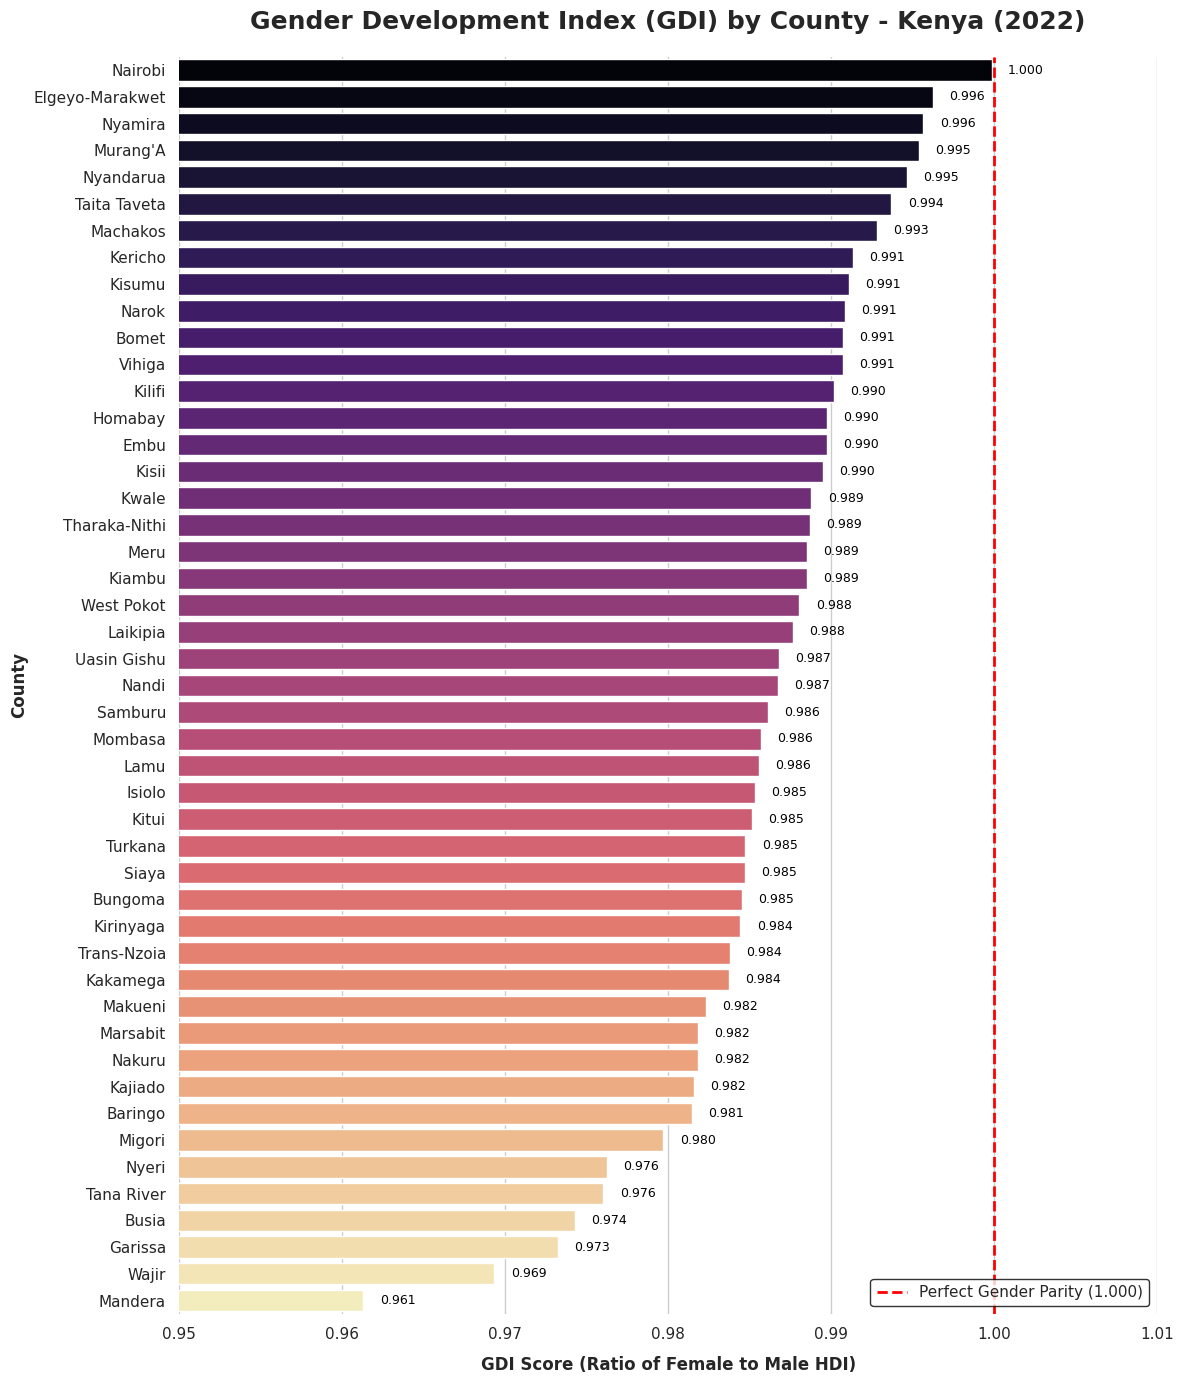

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/gender-development-index/GDI.xlsx")
df_gdi = pd.read_excel(xls, sheet_name='GDI')

# 2. Clean and Filter the Data
# Rename columns based on the structure of the GDI dataset
df_gdi = df_gdi.rename(columns={
    'Unnamed: 1': 'County', 
    'GDI (female / male)': 'GDI'
})

# Exclude the national row ('Kenya') and drop any empty rows
df_plot = df_gdi[~df_gdi['County'].astype(str).str.contains("Kenya", na=False, case=False)].copy()
df_plot = df_plot.dropna(subset=['County', 'GDI'])

# Format county names to Title Case for a professional look
df_plot['County'] = df_plot['County'].astype(str).str.strip().str.title()

# Sort the data from highest GDI (closest to parity) to lowest
df_plot = df_plot.sort_values(by='GDI', ascending=False)

# 3. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 14)) # Tall figure to accommodate all 47 counties

# 4. Create the horizontal barplot
# Using the 'magma' palette (purple to warm pink) to distinguish it from the HDI/IHDI charts
ax = sns.barplot(
    x='GDI', 
    y='County', 
    data=df_plot, 
    palette="magma", 
    hue='County',      
    legend=False
)

# 5. Add a Gender Parity Reference Line
# A GDI of 1.000 represents perfect gender parity in human development capabilities
plt.axvline(x=1.0, color='red', linestyle='--', linewidth=2, label='Perfect Gender Parity (1.000)')

# 6. Add data labels to the end of each bar
for p in ax.patches:
    width = p.get_width()
    if width > 0: 
        ax.text(
            width + 0.001,       # Slight offset to the right of the bar
            p.get_y() + p.get_height() / 2, # Center vertically
            f'{width:.3f}',      # Format to 3 decimal places
            ha='left', 
            va='center', 
            fontsize=9,
            color='black'
        )

# 7. Formatting the plot
plt.title("Gender Development Index (GDI) by County - Kenya (2022)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("GDI Score (Ratio of Female to Male HDI)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("County", fontsize=12, fontweight='bold')

# Focus the X-axis between 0.95 and 1.01 to clearly show the variance between counties
plt.xlim(0.95, 1.01) 

# Add legend for the parity line
plt.legend(loc='lower right', fontsize=11, frameon=True, facecolor='white', edgecolor='black')

# Remove the top and right spines for a cleaner look
sns.despine(left=True, bottom=True)

plt.tight_layout()

# 8. Save the plot as a downloadable high-resolution PNG file in Kaggle
# plt.savefig('kenya_gdi_by_county_ranked.png', dpi=300, bbox_inches='tight')

plt.show()

## Multidimensional Poverty Index

### 1. Urban vs. Rural MPI comparison

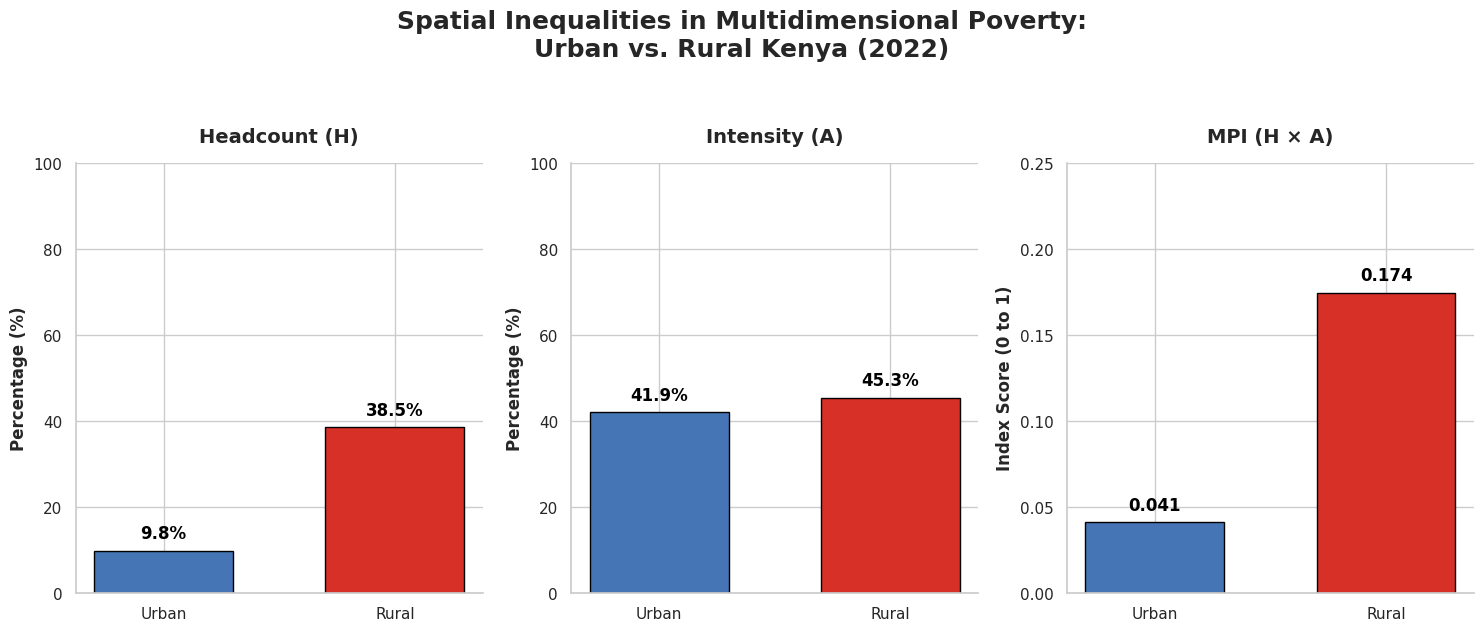

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the Data
# The correct filename in the environment is "MPI by Residence and County.xlsx"
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/MPI by Residence and County.xlsx")
df = pd.read_excel(xls, sheet_name='County')

# 2. Extract Urban and Rural Metrics
urban_row = df[df['Unnamed: 1'] == 'Urban']
rural_row = df[df['Unnamed: 1'] == 'Rural']

# Extract values (H = Headcount, A = Intensity, MPI = Multidimensional Poverty Index)
metrics = {
    'Urban': {
        'Headcount (H)': urban_row['Unnamed: 4'].values[0] * 100, # Convert to percentage for display
        'Intensity (A)': urban_row['Unnamed: 8'].values[0] * 100, # Convert to percentage for display
        'MPI (H × A)': urban_row['Unnamed: 10'].values[0] # Keep as index score (0 to 1)
    },
    'Rural': {
        'Headcount (H)': rural_row['Unnamed: 4'].values[0] * 100,
        'Intensity (A)': rural_row['Unnamed: 8'].values[0] * 100,
        'MPI (H × A)': rural_row['Unnamed: 10'].values[0]
    }
}

# 3. Set up the plotting environment
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=False) # 3 separate panels for clarity

categories = ['Urban', 'Rural']
colors = ['#4575b4', '#d73027'] # Blue for Urban, Red for Rural

# 4. Plot each metric in its own subplot
metric_names = ['Headcount (H)', 'Intensity (A)', 'MPI (H × A)']
y_labels = ['Percentage (%)', 'Percentage (%)', 'Index Score (0 to 1)']
max_ylims = [100, 100, 0.25] # Set logical maximums for the Y-axes

for i, metric in enumerate(metric_names):
    ax = axes[i]
    values = [metrics['Urban'][metric], metrics['Rural'][metric]]
    
    bars = ax.bar(categories, values, color=colors, edgecolor='black', width=0.6)
    
    # Formatting
    ax.set_title(metric, fontsize=14, fontweight='bold', pad=15)
    ax.set_ylabel(y_labels[i], fontsize=12, fontweight='bold')
    ax.set_ylim(0, max_ylims[i])
    
    # Add data labels on top of the bars
    for bar in bars:
        height = bar.get_height()
        # Format as percentage for H and A, and as a 3-decimal float for MPI
        label_text = f'{height:.1f}%' if i < 2 else f'{height:.3f}'
        ax.text(
            bar.get_x() + bar.get_width() / 2, 
            height + (max_ylims[i] * 0.02), # Offset slightly above the bar
            label_text, 
            ha='center', 
            va='bottom', 
            fontsize=12,
            fontweight='bold',
            color='black'
        )
    
    sns.despine(ax=ax)

# 5. Main Title and Layout
fig.suptitle("Spatial Inequalities in Multidimensional Poverty:\nUrban vs. Rural Kenya (2022)", 
             fontsize=18, fontweight='bold', y=1.05)

plt.tight_layout()

# 6. Save the graphic
# plt.savefig('kenya_mpi_urban_vs_rural.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### 2. Kenya MPI Incidence Map by County

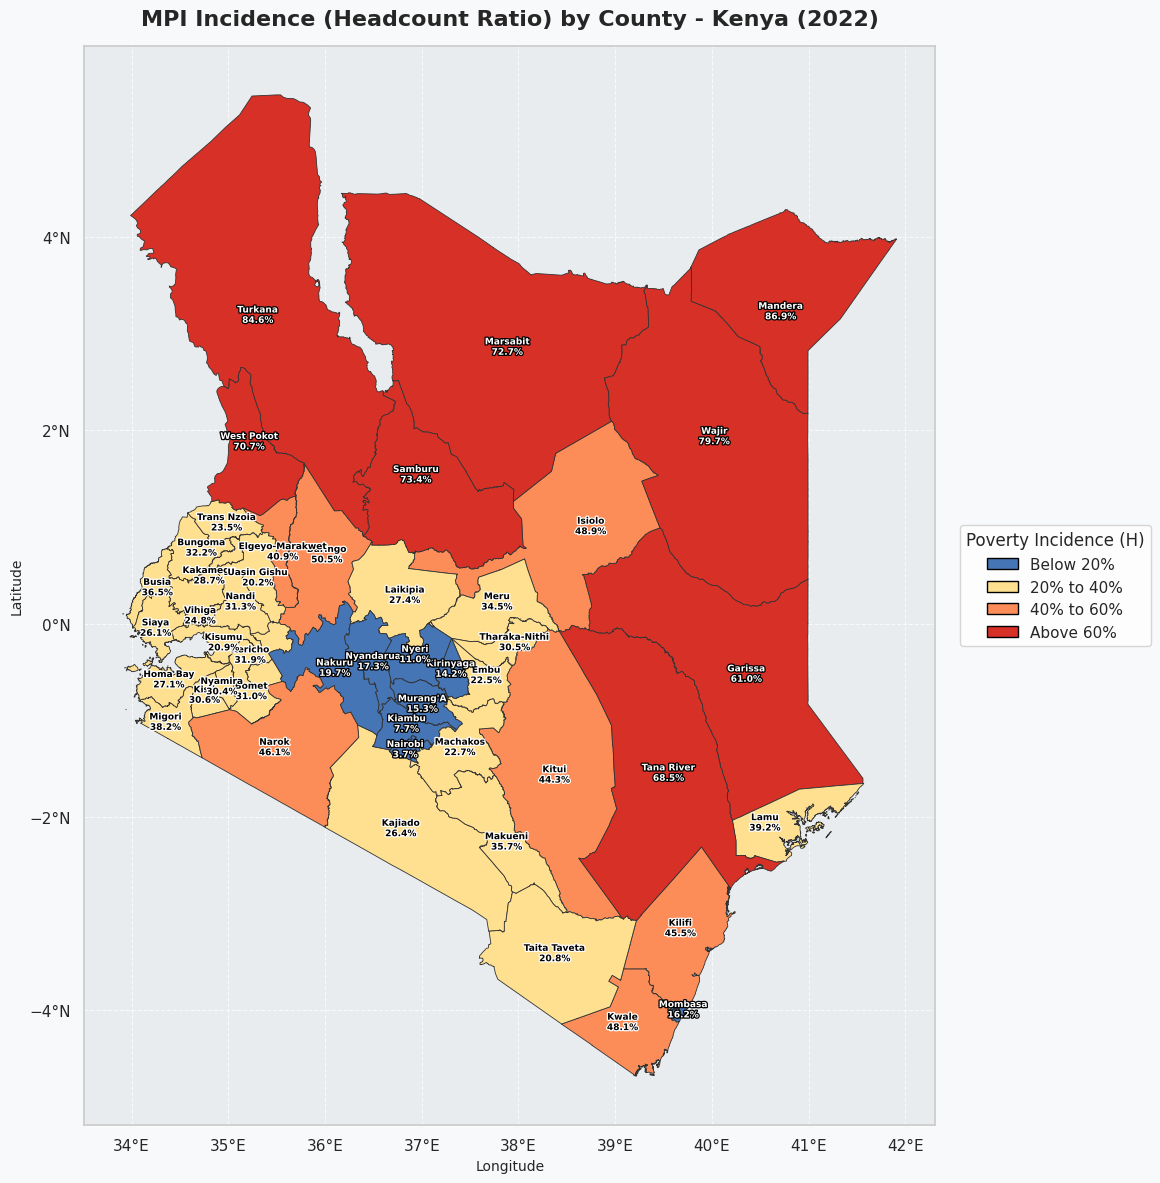

In [25]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patheffects as path_effects

# 1. Load Geospatial Data
# Replace with the actual path to your Kenya counties shapefile in Kaggle
gdf = gpd.read_file('/kaggle/input/datasets/lekakeny/kenya-counties-map/ke_county.shp') 
gdf['County_Name'] = gdf['county'].str.strip().str.title()


# 2. Load the Updated MPI Data
# Using the newly attached file verbatim
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/MPI by Residence and County.xlsx")
mpi_data = pd.read_excel(xls, sheet_name='County')

# Extract the county rows (skipping the national/urban/rural headers in the first 5 rows)
# We drop rows where the MPI value (column index 10) is empty to ensure we only get valid counties
mpi_data = mpi_data.iloc[5:].dropna(subset=[mpi_data.columns[10]]).copy()

# Rename the relevant columns ('Unnamed: 1' is County, 'Unnamed: 4' is Incidence H)
mpi_data = mpi_data.rename(columns={
    'Unnamed: 1': 'County',
    'Unnamed: 4': 'Incidence_H'
})

# Format County names and convert Incidence to a percentage (0-100 scale)
mpi_data['County'] = mpi_data['County'].astype(str).str.strip().str.title()
mpi_data['Incidence_H'] = pd.to_numeric(mpi_data['Incidence_H']) * 100

# 3. Merge Geospatial and MPI Data
map_data = gdf.merge(mpi_data, left_on='County_Name', right_on='County', how='left')

# 4. Categorize MPI Incidence Values (4 active bins)
# Bins: <20%, 20-40%, 40-60%, >60%
bins = [0.0, 20.0, 40.0, 60.0, 100.0]
labels = ['Below 20%', '20% to 40%', '40% to 60%', 'Above 60%']

map_data['Incidence_Category'] = pd.cut(map_data['Incidence_H'], bins=bins, labels=labels, right=False)

# Color palette: Blue (Low Poverty Incidence) to Red (High Poverty Incidence)
color_mapping = {
    'Below 20%': '#4575b4',  # Deep Blue (Lowest Incidence)
    '20% to 40%': '#fee090', # Warm Light Yellow 
    '40% to 60%': '#fc8d59', # Orange 
    'Above 60%': '#d73027'   # Soft Red (Highest Incidence)
}

# Assign colors. Fill unmatched counties with a neutral gray.
map_data['Color'] = map_data['Incidence_Category'].map(color_mapping)

# 5. Plotting Setup
fig, ax = plt.subplots(1, 1, figsize=(12, 12), facecolor='#f8f9fa')
ax.set_facecolor('#e9ecef')

# Plot base map
map_data.plot(
    ax=ax, 
    color=map_data['Color'], 
    edgecolor='#333333', 
    linewidth=0.6
)

# 6. Add Enhanced County Labels & Values
for idx, row in map_data.iterrows():
    if pd.notna(row['Incidence_H']):
        # Format label to show County Name and Incidence Percentage
        label_text = f"{row['County']}\n{row['Incidence_H']:.1f}%"
        
        # Guarantee the point is inside the county polygon
        point = row['geometry'].representative_point()
        x, y = point.x, point.y
        
        # Determine text color dynamically based on background contrast
        category = str(row['Incidence_Category'])
        text_color = 'white' if category in ['Below 20%', 'Above 60%'] else 'black'
        stroke_color = 'black' if text_color == 'white' else 'white'

        txt = ax.annotate(
            text=label_text, 
            xy=(x, y), 
            fontsize=6.5, 
            ha='center', 
            va='center',
            color=text_color,
            weight='bold'
        )
        
        # Add stroke/halo effect around text so it pops on any fill color
        txt.set_path_effects([
            path_effects.withStroke(linewidth=1.8, foreground=stroke_color)
        ])

# 7. Formatting & Legend
plt.title("MPI Incidence (Headcount Ratio) by County - Kenya (2022)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Longitude", fontsize=10)
plt.ylabel("Latitude", fontsize=10)

# Create legend 
legend_elements = [
    Patch(facecolor=color_mapping[label], edgecolor='black', label=label) 
    for label in labels
]

ax.legend(
    handles=legend_elements, 
    loc='center left', 
    bbox_to_anchor=(1.02, 0.5), 
    title="Poverty Incidence (H)",
    frameon=True,
    facecolor='white'
)

ax.grid(True, color='white', linestyle='--', linewidth=0.8, alpha=0.7)
ax.xaxis.set_major_formatter('{x:1.0f}°E')
ax.yaxis.set_major_formatter('{x:1.0f}°N')

plt.tight_layout()

# 8. Save the figure to Kaggle working directory
# plt.savefig('kenya_mpi_incidence_map_updated.png', dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())

plt.show()

### 3. Comparing Highest MPI vs. Lowest MPI Counties

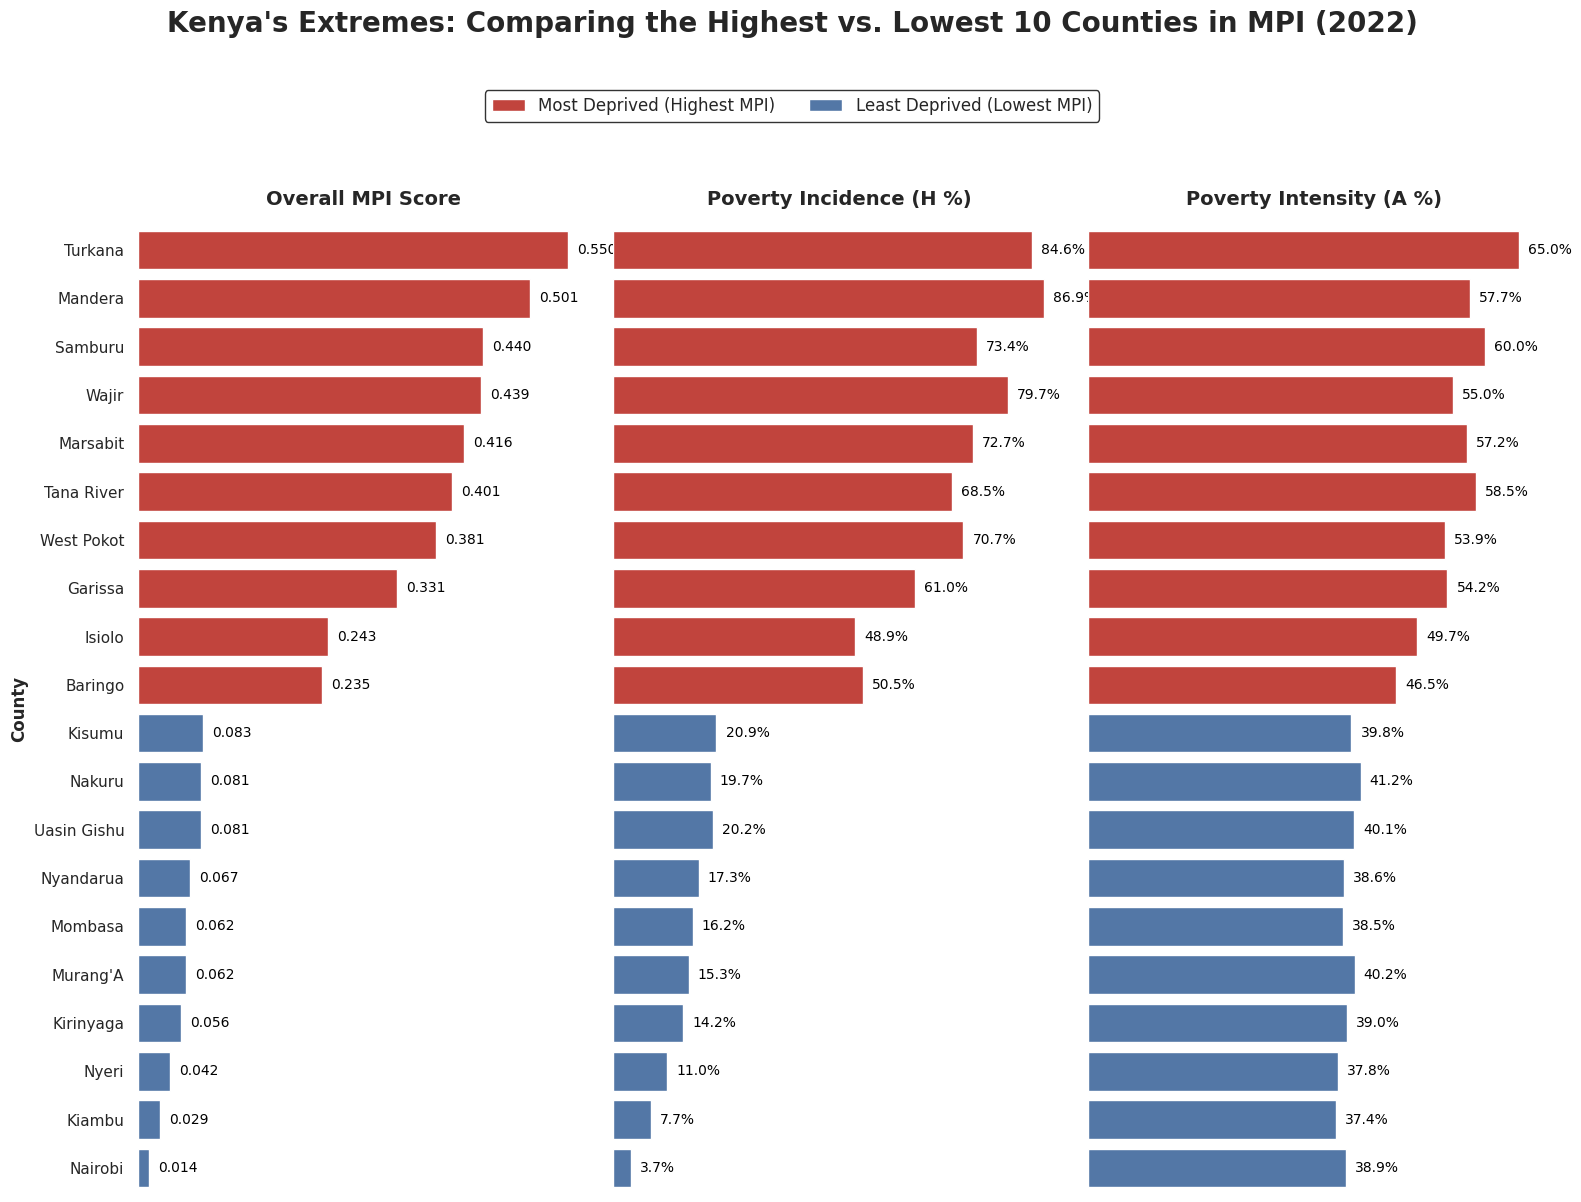

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the Data
xls = pd.ExcelFile("/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/MPI by Residence and County.xlsx")
df = pd.read_excel(xls, sheet_name='County')

# 2. Clean and Extract Core Metrics
# Skip headers/national data (first 5 rows) and drop empty rows based on MPI column (index 10)
counties_df = df.iloc[5:].dropna(subset=[df.columns[10]]).copy()

# Rename columns for clarity based on the MPI framework
counties_df = counties_df.rename(columns={
    'Unnamed: 1': 'County',
    'Unnamed: 4': 'Incidence_H',
    'Unnamed: 8': 'Intensity_A',
    'Unnamed: 10': 'MPI'
})

# Format names and convert data types
counties_df['County'] = counties_df['County'].astype(str).str.strip().str.title()
counties_df['MPI'] = pd.to_numeric(counties_df['MPI'])
# Convert Incidence and Intensity to percentages for better readability
counties_df['Incidence_H'] = pd.to_numeric(counties_df['Incidence_H']) * 100
counties_df['Intensity_A'] = pd.to_numeric(counties_df['Intensity_A']) * 100

# 3. Filter Top 10 and Bottom 10 Counties
# Sort descending by MPI
counties_df = counties_df.sort_values(by='MPI', ascending=False)

highest_10 = counties_df.head(10).copy()
highest_10['Category'] = 'Most Deprived (Highest MPI)'

lowest_10 = counties_df.tail(10).copy()
lowest_10['Category'] = 'Least Deprived (Lowest MPI)'

# Combine into a single comparison DataFrame
comparison_df = pd.concat([highest_10, lowest_10])

# 4. Plotting Setup (1x3 Panel Chart)
sns.set_theme(style="white")
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 12), sharey=True)

metrics = ['MPI', 'Incidence_H', 'Intensity_A']
titles = ['Overall MPI Score', 'Poverty Incidence (H %)', 'Poverty Intensity (A %)']

# Define a custom color palette based on category
palette = {'Most Deprived (Highest MPI)': '#d73027', 'Least Deprived (Lowest MPI)': '#4575b4'}

# 5. Create the Subplots
for i in range(3):
    ax = axes[i]
    metric = metrics[i]
    
    sns.barplot(
        x=metric, 
        y='County', 
        data=comparison_df, 
        hue='Category', 
        palette=palette,
        dodge=False, # Keeps bars aligned properly
        ax=ax
    )
    
    # Add data labels
    for p in ax.patches:
        width = p.get_width()
        if width > 0: 
            # Format MPI to 3 decimals, H and A to 1 decimal percentage
            label_text = f'{width:.3f}' if i == 0 else f'{width:.1f}%'
            ax.text(
                width + (ax.get_xlim()[1] * 0.02), # Dynamic slight offset
                p.get_y() + p.get_height() / 2, 
                label_text, 
                ha='left', 
                va='center', 
                fontsize=10,
                color='black'
            )
            
    # Subplot Formatting
    ax.set_title(titles[i], fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("")
    
    if i == 0:
        ax.set_ylabel("County", fontsize=12, fontweight='bold')
    else:
        ax.set_ylabel("")
        
    ax.set_xticks([]) # Remove bottom x-ticks
    
    # Remove individual legends to create one unified legend at the top
    ax.get_legend().remove()
    
    sns.despine(ax=ax, bottom=True, left=True)

# 6. Unified Legend and Main Title
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.94), 
           ncol=2, fontsize=12, frameon=True, facecolor='white', edgecolor='black')

fig.suptitle("Kenya's Extremes: Comparing the Highest vs. Lowest 10 Counties in MPI (2022)", 
             fontsize=20, fontweight='bold', y=1.0) # Changed y to 1.0

# Adjust layout to accommodate the legend and titles
plt.tight_layout()
plt.subplots_adjust(top=0.82, wspace=0.05) # Lowered top from 0.88 to 0.82

# 7. Save the figure
# plt.savefig('kenya_mpi_top_vs_bottom_10.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### 4. Percentage Contribution of Health, Education, and Living Standards to National MPI

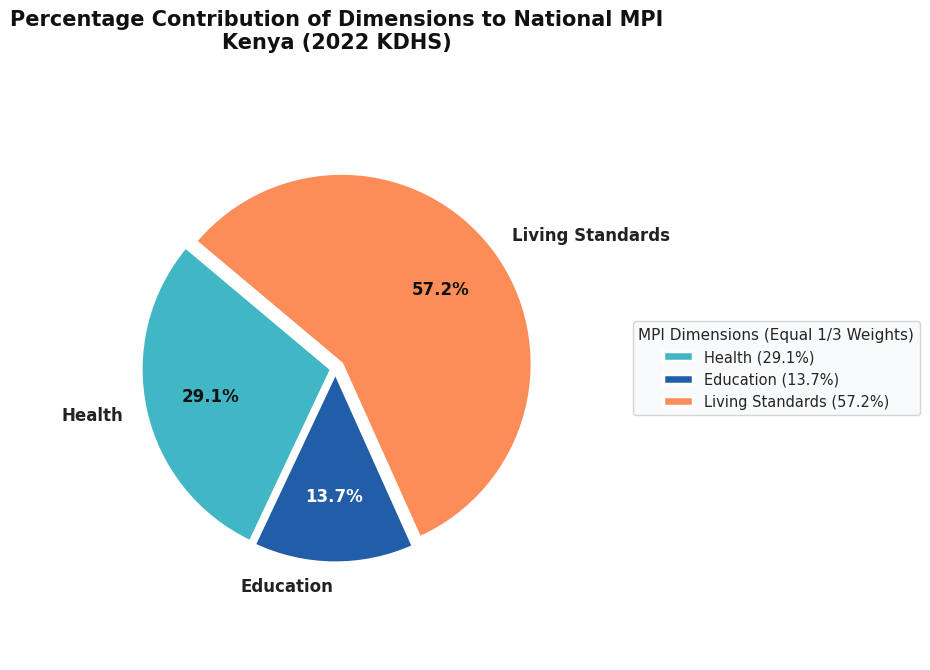

In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Data from the '6_Contribution' sheet
# Automatically resolves the uploaded filename in Kaggle
file_path = "/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/National MPI_2022 KDHS.xlsx" if os.path.exists("/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/National MPI_2022 KDHS.xlsx") else "/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/National MPI_2022 KDHS.xlsx"
xls = pd.ExcelFile(file_path)
df_contrib = pd.read_excel(xls, sheet_name='6_Contribution')

# Extract the dimensional summary rows (rows 17 to 19: Health, Education, Living standards)
dim_df = df_contrib.iloc[17:20, [0, 6]].copy()
dim_df.columns = ['Dimension', 'Contribution']
dim_df['Dimension'] = dim_df['Dimension'].str.strip().str.title()
dim_df['Percentage'] = pd.to_numeric(dim_df['Contribution']) * 100

# 2. Plotting Setup
fig, ax = plt.subplots(figsize=(9, 7), facecolor='white')

# High-contrast palette aligned with KNHDR report visuals
colors = ['#41b6c4', '#225ea8', '#fc8d59']  # Teal (Health), Deep Blue (Education), Warm Orange (Living Standards)
explode = (0.02, 0.02, 0.04)  # Slightly separate Living Standards as the primary driver

wedges, texts, autotexts = ax.pie(
    dim_df['Percentage'],
    labels=dim_df['Dimension'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.65,
    labeldistance=1.12,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5},
    textprops={'fontsize': 12, 'fontweight': 'bold', 'color': '#222222'}
)

# Style percentage labels inside the slices for high contrast
for i, autotext in enumerate(autotexts):
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    autotext.set_color('white' if i == 1 else '#111111')

# 3. Title, Legend & Formatting
ax.set_title(
    "Percentage Contribution of Dimensions to National MPI\nKenya (2022 KDHS)",
    fontsize=15,
    fontweight='bold',
    pad=20,
    color='#111111'
)

legend_labels = [
    f"{row['Dimension']} ({row['Percentage']:.1f}%)"
    for _, row in dim_df.iterrows()
]
ax.legend(
    wedges,
    legend_labels,
    title="MPI Dimensions (Equal 1/3 Weights)",
    title_fontsize=11,
    fontsize=10.5,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor='#f8f9fa',
    edgecolor='#cccccc'
)

ax.axis('equal')  # Ensures a perfect circle
plt.tight_layout()

# 4. Save high-resolution PNG for Kaggle output & report insertion
# plt.savefig('kenya_mpi_dimensional_contribution_pie.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### 5. 10 MPI Indicators by their specific percentage contribution

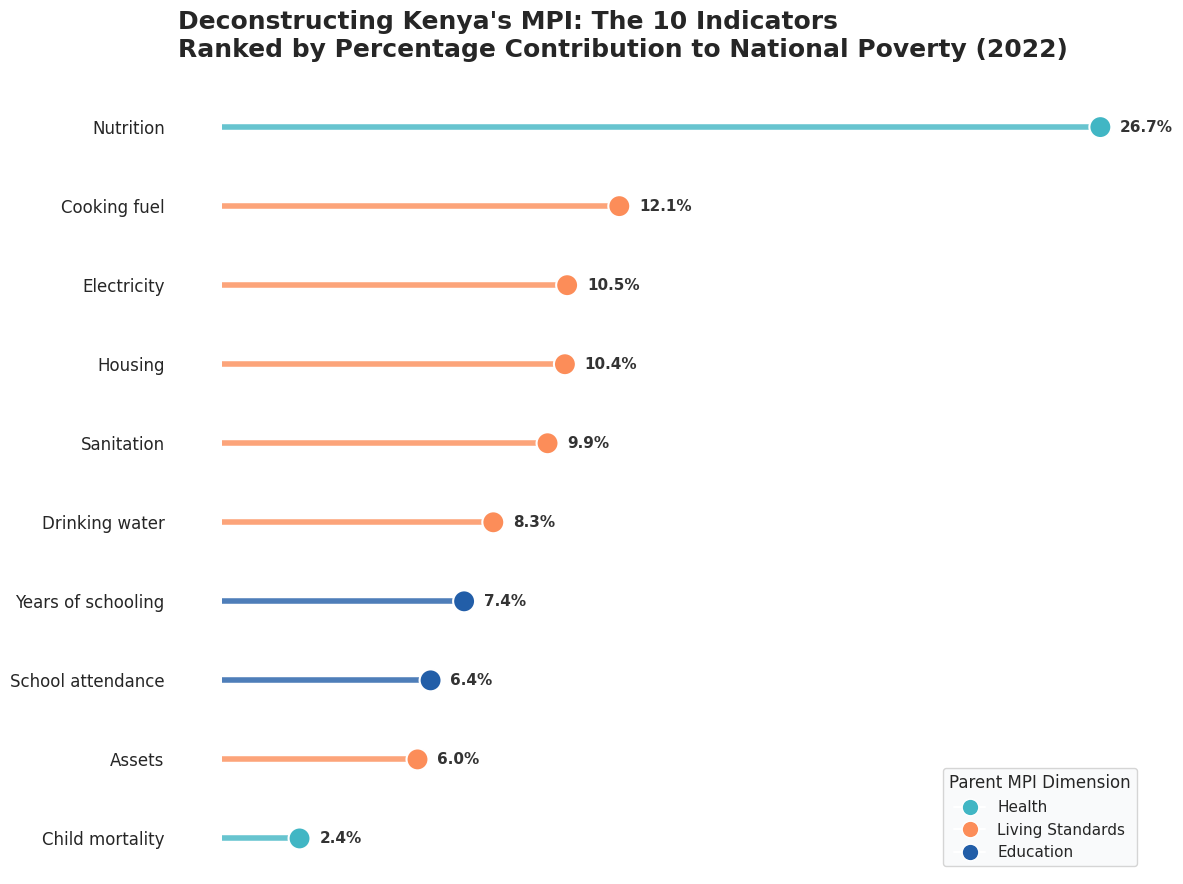

In [28]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1. Load Data from the '6_Contribution' sheet
file_path = "/kaggle/input/datasets/lekakeny/multidimentional-poverty-index/National MPI_2022 KDHS.xlsx" 
xls = pd.ExcelFile(file_path)
df = pd.read_excel(xls, sheet_name='6_Contribution')

# Extract rows 3 to 12 which contain the 10 specific indicators
ind_df = df.iloc[3:13, [0, 1, 6]].copy()
ind_df.columns = ['Indicator', 'Dimension', 'Percentage']

# Clean string values and convert decimal percentage to a 0-100 scale
ind_df['Indicator'] = ind_df['Indicator'].str.strip()
ind_df['Dimension'] = ind_df['Dimension'].str.strip().str.title()
ind_df['Percentage'] = pd.to_numeric(ind_df['Percentage']) * 100

# Sort by percentage ascending (so the largest value appears at the top of the chart)
ind_df = ind_df.sort_values(by='Percentage', ascending=True)

# 2. Color Mapping 
# Matching the exact palette used in your Dimensional Pie Chart
color_map = {
    'Health': '#41b6c4',            # Teal
    'Education': '#225ea8',         # Deep Blue
    'Living Standards': '#fc8d59'   # Warm Orange
}
ind_df['Color'] = ind_df['Dimension'].map(color_map)

# 3. Plotting Setup - The Lollipop Chart
fig, ax = plt.subplots(figsize=(12, 9), facecolor='white')

# Draw the "Sticks" (horizontal lines)
ax.hlines(
    y=ind_df['Indicator'], 
    xmin=0, 
    xmax=ind_df['Percentage'], 
    color=ind_df['Color'], 
    alpha=0.8, 
    linewidth=4
)

# Draw the "Candy" (scatter dots at the end)
ax.scatter(
    ind_df['Percentage'], 
    ind_df['Indicator'], 
    s=250, # Size of the dot
    color=ind_df['Color'], 
    alpha=1, 
    zorder=3, 
    edgecolor='white', 
    linewidth=1.5
)

# Add exact data labels slightly to the right of each dot
for idx, row in ind_df.iterrows():
    ax.text(
        row['Percentage'] + 0.6, # Offset to the right
        row['Indicator'], 
        f"{row['Percentage']:.1f}%", 
        va='center', 
        ha='left', 
        fontweight='bold', 
        fontsize=11, 
        color='#333333'
    )

# 4. Formatting and Clean-up
ax.set_title(
    "Deconstructing Kenya's MPI: The 10 Indicators\nRanked by Percentage Contribution to National Poverty (2022)", 
    fontsize=18, 
    fontweight='bold', 
    pad=25, 
    loc='left'
)

# Improve Y-axis label styling
ax.tick_params(axis='y', labelsize=12)

# Remove all standard borders and X-axis ticks to rely entirely on the data labels
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([]) 
sns.despine(left=True, bottom=True)
ax.grid(False)

# 5. Custom Legend for Dimensions
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Health', markerfacecolor='#41b6c4', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Living Standards', markerfacecolor='#fc8d59', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Education', markerfacecolor='#225ea8', markersize=12)
]

ax.legend(
    handles=legend_elements, 
    loc='lower right', 
    title="Parent MPI Dimension", 
    fontsize=11, 
    title_fontsize=12, 
    frameon=True,
    facecolor='#f8f9fa',
    edgecolor='#cccccc'
)

plt.tight_layout()

# 6. Save the graphic
# plt.savefig('kenya_mpi_10_indicators_lollipop.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()